# CA2 Group 6

# 1. Data Understanding and Preparation

We're predicting loan default.
We start with raw data and end with a clean model-ready feature table.
We build this gradually:
  explore the raw data,
  fix problems (missing values, outliers, duplicates, etc.),
  encode it so a model can use it.

At the end we produce:
- `X` (features)
- `Y` (target)


In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Load the raw dataset
df_raw = pd.read_csv("/content/drive/My Drive/Colab Notebooks/train.csv")

print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (8308, 36)


,income,owns_a_car,owns_a_bike,has_an_active_loan,owns_a_house,nr_children,credit,loan_annuity,accompanied_by,income_type,...,weekday_of_application,hour_of_application,same_residence_and_home,same_work_and_home,score_1,score_2,score_3,nr_defaults_in_social_circle,inquiries_in_last_year,has_defaulted
0,15750.0,False,False,False,False,1,149963.84,4397.85,Alone,Service,...,2,8.0,True,True,0.435028,0.564752,0.673830,True,3.0,0
1,27000.0,True,False,False,True,0,28440.00,1913.40,Alone,Service,...,4,13.0,True,True,0.268014,0.684114,0.493863,True,6.0,0
2,11250.0,False,True,True,False,0,36000.00,2066.40,Alone,Service,...,3,19.0,True,True,0.453478,0.249441,0.755740,True,1.0,0
3,27000.0,False,False,True,True,0,76022.55,3233.70,Alone,Service,...,2,15.0,True,True,0.302776,0.649914,0.689479,True,2.0,0
4,15750.0,False,False,True,True,3,128835.00,3780.00,Alone,Commercial,...,2,14.0,True,True,0.550303,0.619878,0.835777,True,1.0,0


We want to get a feel for numeric columns, categorical columns, target balance and if anything immediately looks weird.

We'll also create `age_in_years` from `age_in_days` just to make things easier to read.


In [5]:
# Add age in years for readability
df_raw = df_raw.copy()
df_raw["age_in_years"] = df_raw["age_in_days"] / 365.25

# Shape
rows, cols = df_raw.shape
print(f"Dataset size: {rows} rows × {cols} columns")

# Numeric summary
num_desc = df_raw.describe(include=[np.number]).T
num_desc["iqr"] = num_desc["75%"] - num_desc["25%"]
num_desc["n_unique"] = df_raw.select_dtypes(include=[np.number]).nunique()
num_desc["missing"] = df_raw.select_dtypes(include=[np.number]).isna().sum()
num_desc["missing_%"] = (
    df_raw.select_dtypes(include=[np.number]).isna().mean() * 100
)

print("\nNumeric summary:")
display(num_desc)

# Categorical and boolean summary
cat_desc = df_raw.describe(include=['object', 'bool']).T
cat_desc = cat_desc.rename(columns={
    "unique": "n_unique",
    "top": "mode",
    "freq": "mode_freq"
})
cat_desc["missing"] = df_raw[cat_desc.index].isna().sum()
cat_desc["missing_%"] = df_raw[cat_desc.index].isna().mean() * 100
cat_desc["mode_freq_%"] = cat_desc["mode_freq"] / len(df_raw) * 100

print("\nCategorical and boolean summary:")
display(cat_desc)

# Target distribution
default_counts = df_raw["has_defaulted"].value_counts().sort_index()
print("\nTarget distribution (has_defaulted):")
print(default_counts)
print("Default rate (% rows with 1):", round(100 * default_counts[1] / len(df_raw), 2), "%")

Dataset size: 8308 rows × 37 columns

Numeric summary:


,count,mean,std,min,25%,50%,75%,max,iqr,n_unique,missing,missing_%
income,8308.0,19423.244179,11384.515832,3600.000000,12600.000000,16812.000000,22500.000000,225000.000000,9900.000000,232,0,0.0
nr_children,8308.0,0.549711,0.779266,0.000000,0.000000,0.000000,1.000000,12.000000,1.000000,9,0,0.0
credit,8308.0,64350.704853,42933.182637,4500.000000,28898.887500,54000.000000,88900.875000,315000.000000,60001.987500,1625,0,0.0
loan_annuity,8308.0,2929.035430,1542.174857,297.900000,1809.337500,2670.300000,3751.650000,22500.000000,1942.312500,3636,0,0.0
education_level,8308.0,1.405633,0.509098,0.000000,1.000000,1.000000,2.000000,4.000000,1.000000,4,0,0.0
residence_density,8308.0,0.022183,0.015521,0.001276,0.010032,0.019101,0.028663,0.072508,0.018631,78,0,0.0
age_in_days,8308.0,14243.894921,3355.501833,7708.000000,11576.500000,13962.000000,16567.000000,24953.000000,4990.500000,5743,0,0.0
consecutive_days_of_employment,8308.0,2348.052480,2260.992994,9.000000,770.750000,1638.000000,3137.000000,16452.000000,2366.250000,4080,0,0.0
nr_days_since_last_registration_change,8308.0,4562.947280,3214.217874,0.000000,1682.750000,4282.500000,6945.000000,16906.000000,5262.250000,5464,0,0.0
nr_days_since_last_document_change,8308.0,2881.537554,1514.129360,0.000000,1580.250000,3001.000000,4225.000000,6154.000000,2644.750000,4041,0,0.0



Categorical and boolean summary:


,count,n_unique,mode,mode_freq,missing,missing_%,mode_freq_%
owns_a_car,8308,2,False,4975,0,0.000000,59.882041
owns_a_bike,8308,2,False,5427,0,0.000000,65.322581
has_an_active_loan,8308,2,True,4247,0,0.000000,51.119403
owns_a_house,8308,2,True,5672,0,0.000000,68.271545
accompanied_by,8308,6,Alone,6888,0,0.000000,82.90804
income_type,8026,3,Service,4757,282,3.394319,57.258065
marital_status,8308,4,M,6097,0,0.000000,73.387097
is_male,8308,1,False,8308,0,0.000000,100.0
type_of_contract,8308,2,CL,7396,0,0.000000,89.022629
type_of_housing,8308,6,Home,7268,0,0.000000,87.481945



Target distribution (has_defaulted):
has_defaulted
0    7723
1     585
Name: count, dtype: int64
Default rate (% rows with 1): 7.04 %


## 1.1 Visual EDA

We'll plot histograms for important numeric features, bar chart for the default balance, scatter of income vs credit, correlation heatmap to see which columns are basically the same info.


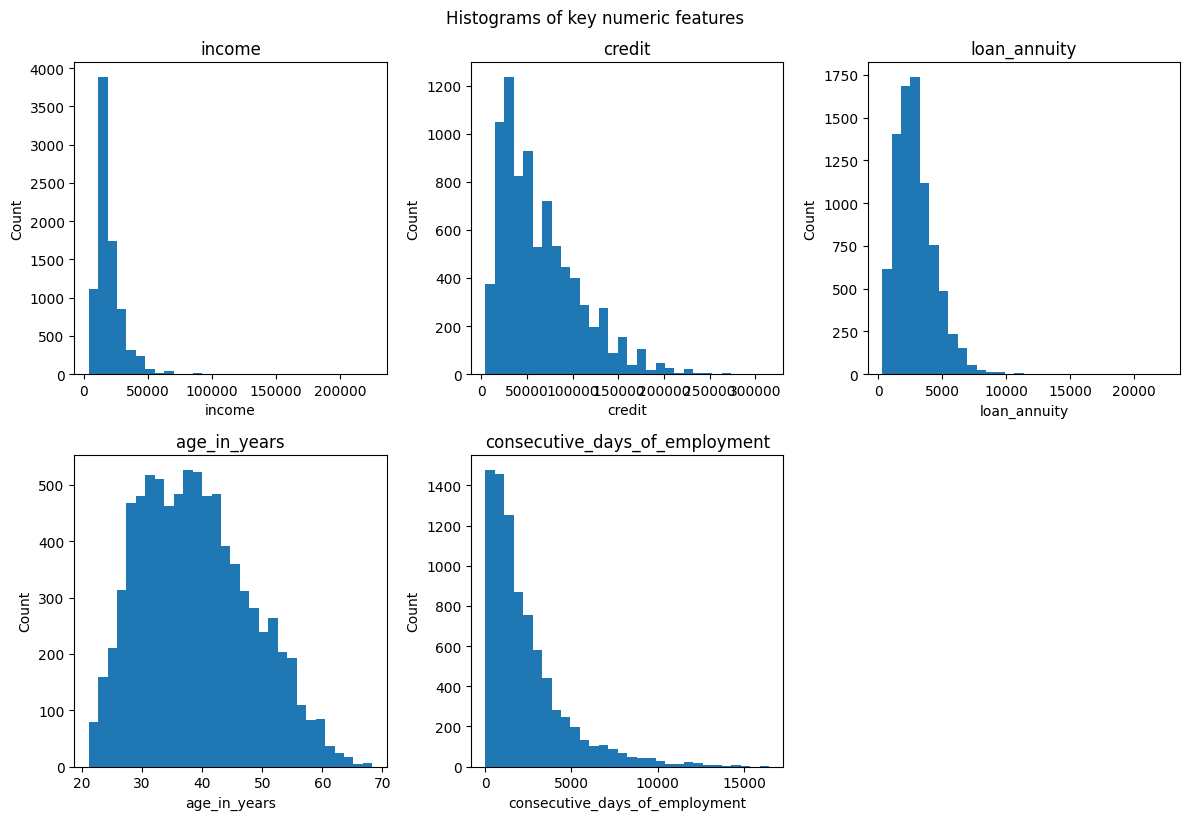

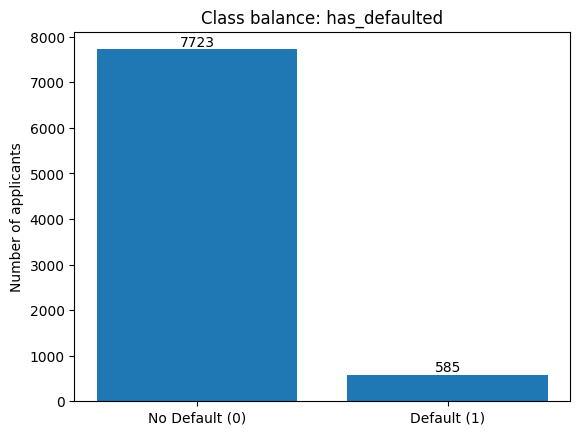

In [6]:
# Histograms for key numeric features
df_raw["age_in_years"] = df_raw["age_in_days"] / 365.25

numeric_for_hist = [
    "income",
    "credit",
    "loan_annuity",
    "age_in_years",
    "consecutive_days_of_employment"
]

plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_for_hist, start=1):
    plt.subplot(2, 3, i)
    plt.hist(df_raw[col].dropna(), bins=30)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Count")

plt.tight_layout()
plt.suptitle("Histograms of key numeric features", y=1.02)
plt.show()

# Class balance plot
default_counts = df_raw["has_defaulted"].value_counts().sort_index()
plt.figure()
plt.bar(["No Default (0)", "Default (1)"], default_counts.values)
plt.title("Class balance: has_defaulted")
plt.ylabel("Number of applicants")
for i, v in enumerate(default_counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.show()

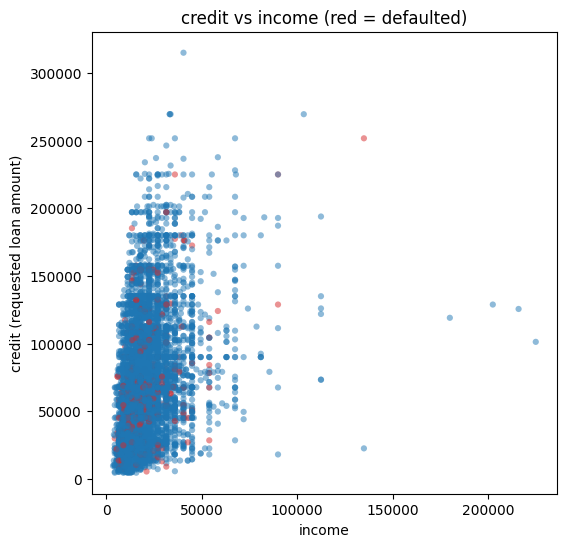

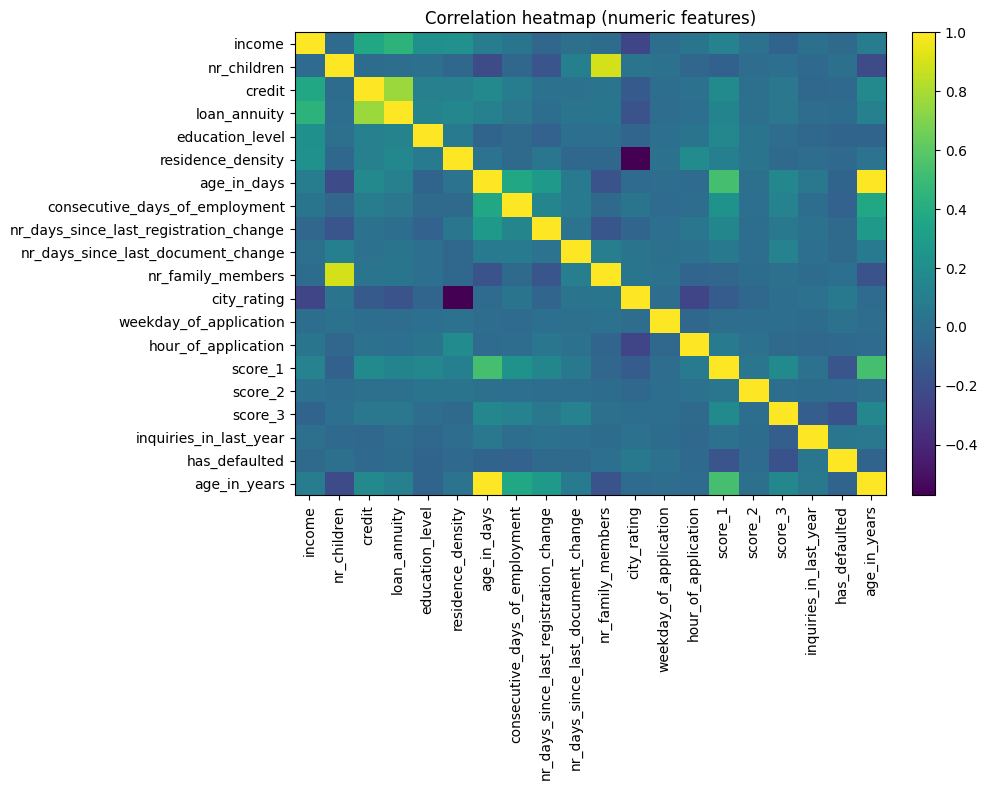

In [7]:
# Scatter: credit vs income
colors = df_raw["has_defaulted"].map({0: "tab:blue", 1: "tab:red"})

plt.figure(figsize=(6,6))
plt.scatter(
    df_raw["income"],
    df_raw["credit"],
    c=colors,
    alpha=0.5,
    s=20,
    edgecolors="none"
)
plt.xlabel("income")
plt.ylabel("credit (requested loan amount)")
plt.title("credit vs income (red = defaulted)")
plt.show()

# Correlation heatmap for numeric columns
numeric_cols_all = df_raw.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df_raw[numeric_cols_all].corr()

plt.figure(figsize=(10,8))
im = plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(numeric_cols_all)), numeric_cols_all, rotation=90)
plt.yticks(range(len(numeric_cols_all)), numeric_cols_all)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.show()

## 1.2 Summary of issues

From the EDA, here are the problems we need to deal with:

- Duplicates: there are exact duplicate rows.
- Constant columns: some columns never change (e.g. always False or always True). They carry no signal.
- Missing data: only `income_type` has missing values (~3.4%). Those rows actually default slightly more.
 We definitely don't want to drop these customers.
- Outliers / extreme values:
 - `income`, `credit`, and `loan_annuity` have huge right tails.
 - `score_2` is mostly between 0 and 1, but one row is literally 100.
 - Employment days can be huge, but that might be legit (long tenure).
- Multicollinearity:
 - `nr_children` and `nr_family_members` are almost the same info (very high correlation).
- Time-of-application:
 - `hour_of_application` is circular (23:00 and 00:00 are “close”).
 - `weekday_of_application` is a category, not a number.

Next, we’ll clean the data step by step and fix each of these.

## 2. Data preparation, step by step

We'll build a clean dataset in stages:

- Step 1: basic cleaning (duplicates, constant columns, types)
- Step 2: missing values
- Step 3: outliers/extreme values
- Step 4: multicollinearity
- Step 5: encoding (turn everything into numeric features)
- Step 6: final model-ready dataset (`X_ready`, `y`)

### Step 1 — Basic cleaning

Here we:
- drop duplicate rows,
- remove columns with no variance (constant for everyone),
- fix obvious data types (like hour of application as an int 0–23),
- check cardinality of each column.

Rows before dropping duplicates: 8308
Rows after dropping duplicates: 7871
Constant columns: ['is_male', 'has_provided_a_mobile_number', 'same_residence_and_home', 'same_work_and_home', 'nr_defaults_in_social_circle']
Shape after Step 1: (7871, 32)


,income,owns_a_car,owns_a_bike,has_an_active_loan,owns_a_house,nr_children,credit,loan_annuity,accompanied_by,income_type,...,nr_family_members,city_rating,weekday_of_application,hour_of_application,score_1,score_2,score_3,inquiries_in_last_year,has_defaulted,age_in_years
0,15750.0,False,False,False,False,1,149963.84,4397.85,Alone,Service,...,3,2,2,8,0.435028,0.564752,0.673830,3.0,0,30.986995
1,27000.0,True,False,False,True,0,28440.00,1913.40,Alone,Service,...,1,2,4,13,0.268014,0.684114,0.493863,6.0,0,27.520876
2,11250.0,False,True,True,False,0,36000.00,2066.40,Alone,Service,...,1,2,3,19,0.453478,0.249441,0.755740,1.0,0,35.507187
3,27000.0,False,False,True,True,0,76022.55,3233.70,Alone,Service,...,2,2,2,15,0.302776,0.649914,0.689479,2.0,0,38.119097
4,15750.0,False,False,True,True,3,128835.00,3780.00,Alone,Commercial,...,5,1,2,14,0.550303,0.619878,0.835777,1.0,0,38.031485


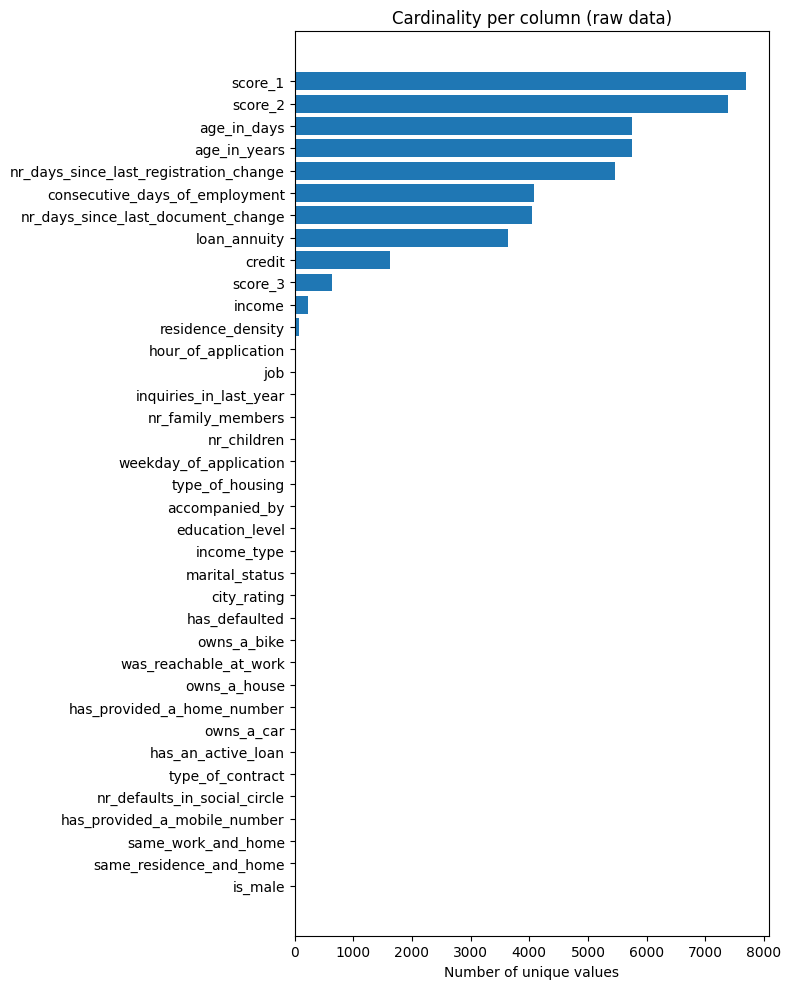

In [8]:
# 1. Start from raw and drop duplicates
df_step1 = df_raw.drop_duplicates().copy()

print("Rows before dropping duplicates:", len(df_raw))
print("Rows after dropping duplicates:", len(df_step1))

# 2. Find and drop constant columns
nunique_per_col = df_step1.nunique(dropna=False)
constant_cols = nunique_per_col[nunique_per_col == 1].index.tolist()
print("Constant columns:", constant_cols)

df_step1 = df_step1.drop(columns=constant_cols)

# 3. Fix obvious data types
df_step1["hour_of_application"] = df_step1["hour_of_application"].astype(int)
df_step1["education_level"] = df_step1["education_level"].astype(int)
df_step1["city_rating"] = df_step1["city_rating"].astype(int)

print("Shape after Step 1:", df_step1.shape)
display(df_step1.head())

# 4. Plot cardinality
cardinality = df_raw.nunique(dropna=False).sort_values()

plt.figure(figsize=(8,10))
plt.barh(cardinality.index.astype(str), cardinality.values)
plt.xlabel("Number of unique values")
plt.title("Cardinality per column (raw data)")
plt.tight_layout()
plt.show()

### Step 2 — Missing values

Only `income_type` has missing values (~3.4%).

Instead of dropping those rows, we keep them and fill `income_type` with `"Unknown"`.
We want `"Unknown"` to survive as a separate category so the model can learn from it.

We'll also confirm that these missing rows actually do have a different default rate.

Missing overview (Step 1):


,missing_count,missing_%
income_type,281,3.570067
income,0,0.000000
owns_a_bike,0,0.000000
owns_a_car,0,0.000000
owns_a_house,0,0.000000
nr_children,0,0.000000
credit,0,0.000000
has_an_active_loan,0,0.000000
loan_annuity,0,0.000000
accompanied_by,0,0.000000


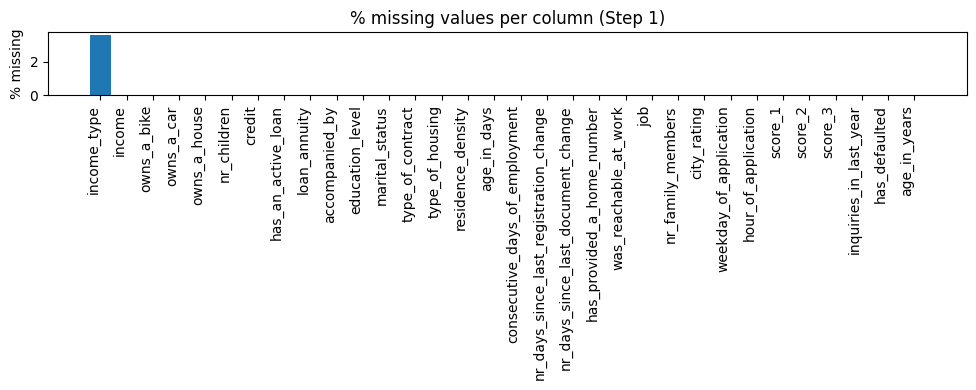

Default rate (income_type missing): 8.9 %
Default rate (income_type present): 7.0 %
Rows after Step 2: (7871, 32)


,count
income_type,
Service,4510
Commercial,2406
Govt Job,674
Unknown,281


In [9]:
# Missingness overview in df_step1
missing_counts = df_step1.isna().sum()
missing_pct = df_step1.isna().mean() * 100
missing_df = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_%": missing_pct
}).sort_values("missing_count", ascending=False)

print("Missing overview (Step 1):")
display(missing_df.head(10))

# Plot % missing per column
plt.figure(figsize=(10,4))
plt.bar(missing_df.index.astype(str), missing_df["missing_%"])
plt.xticks(rotation=90, ha="right")
plt.ylabel("% missing")
plt.title("% missing values per column (Step 1)")
plt.tight_layout()
plt.show()

# Check default rate for rows with and without income_type
mask_missing_income_type = df_step1["income_type"].isna()
default_rate_missing = df_step1.loc[mask_missing_income_type, "has_defaulted"].mean() * 100
default_rate_not_missing = df_step1.loc[~mask_missing_income_type, "has_defaulted"].mean() * 100
print("Default rate (income_type missing):", round(default_rate_missing,2), "%")
print("Default rate (income_type present):", round(default_rate_not_missing,2), "%")

# Create df_step2 by imputing income_type = "Unknown"
df_step2 = df_step1.copy()
df_step2["income_type"] = df_step2["income_type"].fillna("Unknown")

print("Rows after Step 2:", df_step2.shape)
df_step2["income_type"].value_counts(dropna=False).head()

### Step 3 — Outliers / extreme values

Money-style features (`income`, `credit`, `loan_annuity`) have very long right tails.
We don't want to delete those people (they're important, high exposure), we just don't want them to blow up the scale.

What we'll do:
- cap the extreme high tail using the IQR rule (Q3 + 1.5×IQR),
- take log1p of the capped values (log(1 + x)),
- clip `score_2` so that the weird "100" becomes 1.0,
- make a log-style version of employment length too.

We'll keep the original columns for reference, but the model will mainly use the engineered versions.

Rows after Step 3: (7871, 40)


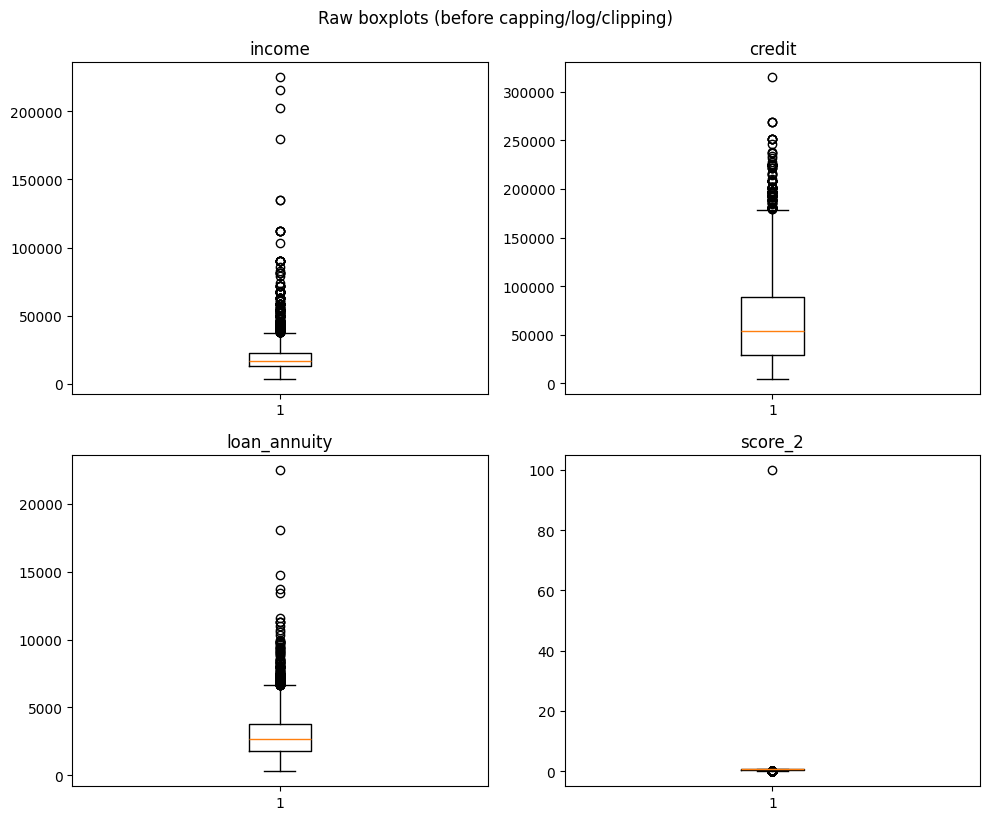

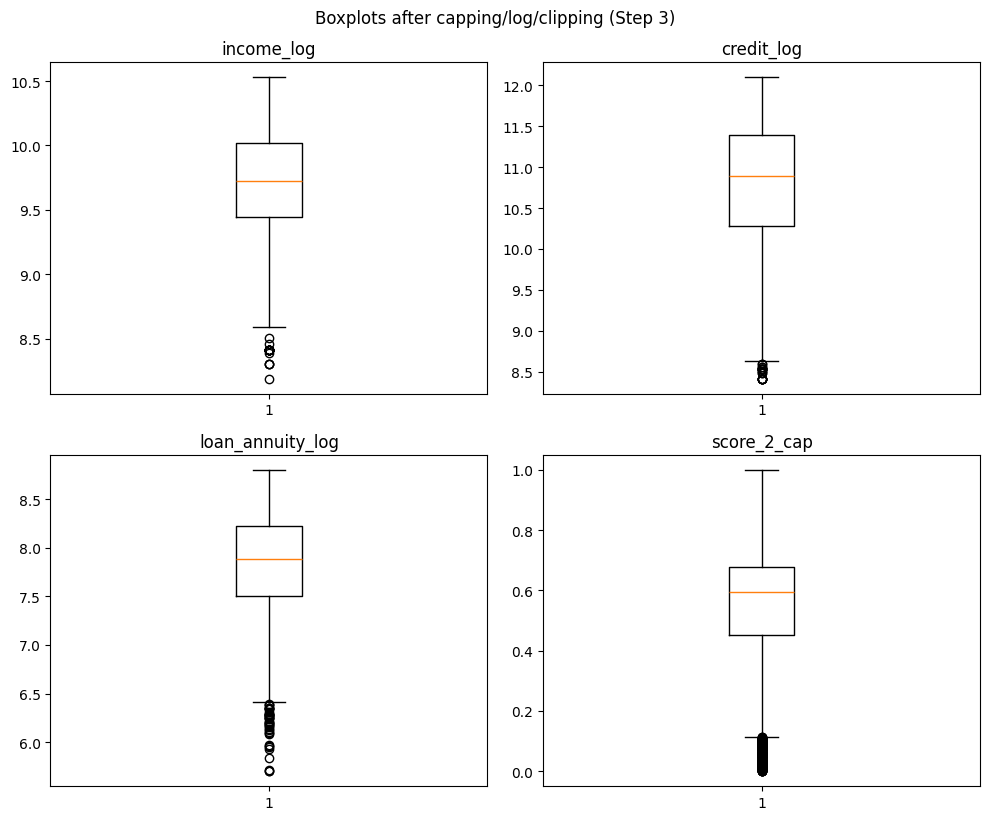

In [10]:
df_step3 = df_step2.copy()

def cap_upper(series):
    # Cap the upper tail using IQR fence
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    return np.minimum(series, upper_fence)

# Cap the high tail for money columns
df_step3["income_cap"] = cap_upper(df_step3["income"])
df_step3["credit_cap"] = cap_upper(df_step3["credit"])
df_step3["loan_annuity_cap"] = cap_upper(df_step3["loan_annuity"])

# Clip score_2 above 1.0
df_step3["score_2_cap"] = np.minimum(df_step3["score_2"], 1.0)

# Log transforms (log1p handles 0 safely)
df_step3["income_log"] = np.log1p(df_step3["income_cap"])
df_step3["credit_log"] = np.log1p(df_step3["credit_cap"])
df_step3["loan_annuity_log"] = np.log1p(df_step3["loan_annuity_cap"])
df_step3["employment_days_log"] = np.log1p(df_step3["consecutive_days_of_employment"])

print("Rows after Step 3:", df_step3.shape)

# Boxplots BEFORE
plt.figure(figsize=(10,8))
for i, col in enumerate(["income","credit","loan_annuity","score_2"], start=1):
    plt.subplot(2,2,i)
    plt.boxplot(df_step2[col].dropna(), vert=True, showfliers=True)
    plt.title(col)
plt.tight_layout()
plt.suptitle("Raw boxplots (before capping/log/clipping)", y=1.02)
plt.show()

# Boxplots AFTER
plt.figure(figsize=(10,8))
for i, col in enumerate(["income_log","credit_log","loan_annuity_log","score_2_cap"], start=1):
    plt.subplot(2,2,i)
    plt.boxplot(df_step3[col].dropna(), vert=True, showfliers=True)
    plt.title(col)
plt.tight_layout()
plt.suptitle("Boxplots after capping/log/clipping (Step 3)", y=1.02)
plt.show()

### Step 4 — Multicollinearity / redundancy

Some columns are almost the same information.
Example: `nr_children` and `nr_family_members` are extremely correlated (around 0.9).
That can mess with simple linear models because they can't tell which one matters.

We'll keep `nr_family_members` and drop `nr_children`.
We'll also re-check correlations so we can screenshot them for the report/slide deck.

Top correlated pairs (Step 3 data):


,feature_A,feature_B,pearson_r,abs_r
159,age_in_days,age_in_years,1.000000,1.000000
71,credit,credit_cap,0.994803,0.994803
96,loan_annuity,loan_annuity_cap,0.975613,0.975613
353,income_cap,income_log,0.969163,0.969163
366,loan_annuity_cap,loan_annuity_log,0.951014,0.951014
360,credit_cap,credit_log,0.930431,0.930431
75,credit,credit_log,0.916758,0.916758
100,loan_annuity,loan_annuity_log,0.914316,0.914316
35,nr_children,nr_family_members,0.894237,0.894237
19,income,income_cap,0.870416,0.870416


Rows after Step 4: (7871, 39)


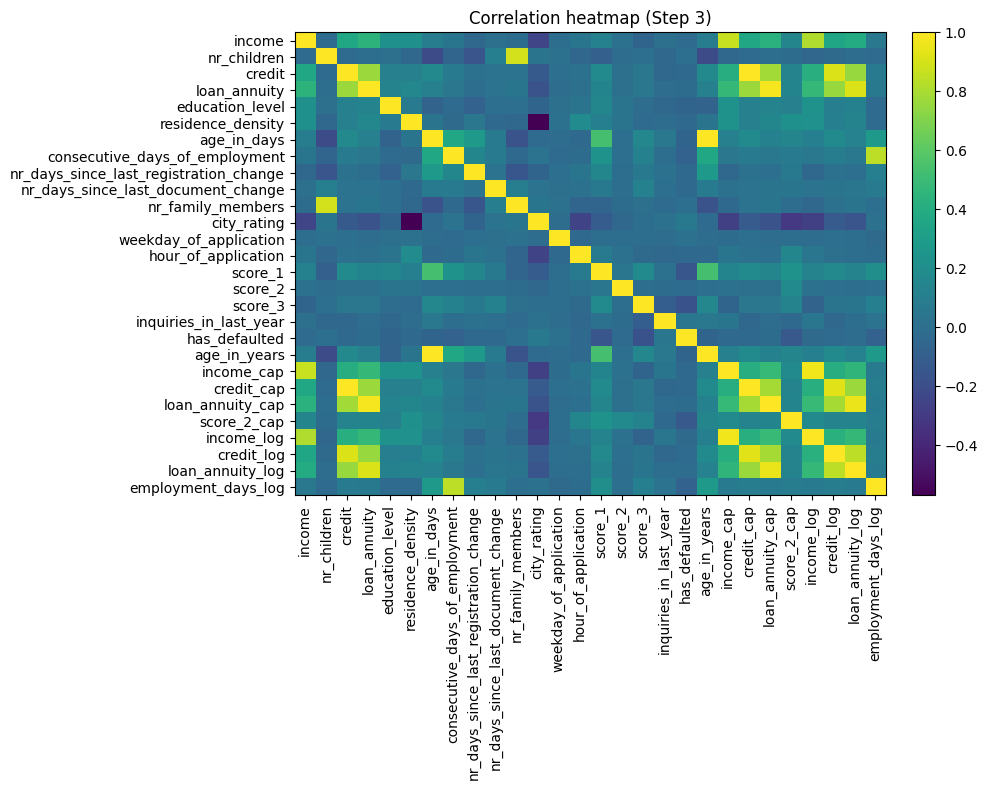

In [11]:
df_step4 = df_step3.copy()

# Check which numeric pairs are highly correlated
numeric_cols_now = df_step4.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix_now = df_step4[numeric_cols_now].corr()

pairs = []
for i, a in enumerate(numeric_cols_now):
    for j, b in enumerate(numeric_cols_now):
        if j <= i:
            continue
        r = corr_matrix_now.loc[a, b]
        pairs.append({
            "feature_A": a,
            "feature_B": b,
            "pearson_r": r,
            "abs_r": abs(r)
        })

corr_pairs_sorted = pd.DataFrame(pairs).sort_values("abs_r", ascending=False)
print("Top correlated pairs (Step 3 data):")
display(corr_pairs_sorted.head(10))

# Drop nr_children because it's redundant with nr_family_members
if "nr_children" in df_step4.columns:
    df_step4 = df_step4.drop(columns=["nr_children"])

print("Rows after Step 4:", df_step4.shape)

# Plot heatmap again
plt.figure(figsize=(10,8))
im = plt.imshow(corr_matrix_now, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(numeric_cols_now)), numeric_cols_now, rotation=90)
plt.yticks(range(len(numeric_cols_now)), numeric_cols_now)
plt.title("Correlation heatmap (Step 3)")
plt.tight_layout()
plt.show()

### Step 5 — Encoding all features

Now we convert everything into numeric features the models can use.

We do:
- binary flags → 0/1 ints
- nominal categories → one-hot encoding (including "Unknown" in `income_type`)
- ordinal categories → keep as integer rank
- weekday → one-hot
- hour → add sin/cos and add five time-band flags


In [12]:
df_step5 = df_step4.copy()

# 1) Binary columns -> cast to int (0/1)
binary_cols = [
    "owns_a_car",
    "owns_a_bike",
    "has_an_active_loan",
    "owns_a_house",
    "has_provided_a_home_number",
    "was_reachable_at_work"
]

for col in binary_cols:
    if col in df_step5.columns:
        df_step5[col] = df_step5[col].astype(int)

# 2) Hour features
if "hour_of_application" in df_step5.columns:
    df_step5["hour_of_application"] = pd.to_numeric(df_step5["hour_of_application"], errors="coerce").fillna(0).astype(int)
    df_step5["hour_of_application"] = df_step5["hour_of_application"].clip(0, 23)

    # Cyclical features
    df_step5["hour_sin"] = np.sin(2 * np.pi * df_step5["hour_of_application"] / 24.0)
    df_step5["hour_cos"] = np.cos(2 * np.pi * df_step5["hour_of_application"] / 24.0)

    # Time bands
    h = df_step5["hour_of_application"]

    df_step5["application_time_pre_open_hours"] = ((h >= 0) & (h <= 9)).astype(int)
    df_step5["application_time_morning_hours"] = ((h >= 10) & (h <= 11)).astype(int)
    df_step5["application_time_lunch_hours"] = ((h >= 12) & (h <= 13)).astype(int)
    df_step5["application_time_afternoon_hours"] = ((h >= 14) & (h <= 17)).astype(int)
    df_step5["application_time_after_hours"] = ((h >= 18) & (h <= 23)).astype(int)

    time_band_cols = [
        "application_time_pre_open_hours",
        "application_time_morning_hours",
        "application_time_lunch_hours",
        "application_time_afternoon_hours",
        "application_time_after_hours"
    ]

    # Add new flags to the binary block so they flow into X later
    binary_cols = list(dict.fromkeys(binary_cols + time_band_cols))

# 3) Columns we want to one-hot encode (nominal / unordered categories)
nominal_cols = [
    "accompanied_by",
    "income_type",
    "marital_status",
    "type_of_contract",
    "type_of_housing",
    "job"
]

weekday_col = ["weekday_of_application"]

ohe_cols = [c for c in (nominal_cols + weekday_col) if c in df_step5.columns]
df_for_ohe = df_step5[ohe_cols].copy()

# Force weekday_of_application to be treated as a category, not a number
if "weekday_of_application" in df_for_ohe.columns:
    df_for_ohe["weekday_of_application"] = df_for_ohe["weekday_of_application"].astype("category")

# 4) One-hot encode
df_ohe = pd.get_dummies(
    df_for_ohe,
    drop_first=True,
    dtype=int
)

# Preview block
print("Step 5 preview:")
print("df_step5 shape:", df_step5.shape)
display(df_step5.head())

print("One-hot preview:")
print("df_ohe shape:", df_ohe.shape)
display(df_ohe.head())


Step 5 preview:
df_step5 shape: (7871, 46)


,income,owns_a_car,owns_a_bike,has_an_active_loan,owns_a_house,credit,loan_annuity,accompanied_by,income_type,education_level,...,credit_log,loan_annuity_log,employment_days_log,hour_sin,hour_cos,application_time_pre_open_hours,application_time_morning_hours,application_time_lunch_hours,application_time_afternoon_hours,application_time_after_hours
0,15750.0,0,0,0,0,149963.84,4397.85,Alone,Service,2,...,11.918156,8.389098,5.913503,0.866025,-0.500000,1,0,0,0,0
1,27000.0,1,0,0,1,28440.00,1913.40,Alone,Service,1,...,10.255587,7.557160,5.966147,-0.258819,-0.965926,0,0,1,0,0
2,11250.0,0,1,1,0,36000.00,2066.40,Alone,Service,1,...,10.491302,7.634047,8.672657,-0.965926,0.258819,0,0,0,0,1
3,27000.0,0,0,1,1,76022.55,3233.70,Alone,Service,2,...,11.238798,8.081691,8.679312,-0.707107,-0.707107,0,0,0,1,0
4,15750.0,0,0,1,1,128835.00,3780.00,Alone,Commercial,2,...,11.766296,8.237744,5.846439,-0.500000,-0.866025,0,0,0,1,0


One-hot preview:
df_ohe shape: (7871, 40)


,accompanied_by_Group,accompanied_by_Kids,accompanied_by_Others,accompanied_by_Partner,accompanied_by_Relative,income_type_Govt Job,income_type_Service,income_type_Unknown,marital_status_M,marital_status_S,...,job_Sales,job_Secretaries,job_Security,job_Waiters/barmen,weekday_of_application_1,weekday_of_application_2,weekday_of_application_3,weekday_of_application_4,weekday_of_application_5,weekday_of_application_6
0,0,0,0,0,0,0,1,0,1,0,...,1,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,0,1,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0


### Step 6 — Scaling

Some models (k-NN, SVM, logistic regression, neural networks) usually train better when continuous numeric inputs sit on a similar scale.

Here we Min-Max scale only the continuous numeric columns. We do not scale binary 0/1 flags and we do not scale one-hot columns (those are already 0/1).

We do not overwrite existing columns. We add scaled copies with an `_mm` suffix into the same table, so we can use them only when we need them.


In [13]:
from sklearn.preprocessing import MinMaxScaler

# We add new _mm columns for scaled features

numeric_cols = df_step5.select_dtypes(include=[np.number]).columns.tolist()

# Never scale the target
if "has_defaulted" in numeric_cols:
    numeric_cols.remove("has_defaulted")

# Identify binary-like columns (only 0/1 values)
binary_like_cols = []
for col in numeric_cols:
    vals = pd.unique(df_step5[col].dropna())
    if len(vals) <= 2 and set(vals).issubset({0, 1}):
        binary_like_cols.append(col)

# Continuous numeric columns to scale (skip any existing _mm columns if the cell is re-run)
continuous_for_scaling = [
    c for c in numeric_cols
    if c not in binary_like_cols and not c.endswith("_mm")
]

scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df_step5[continuous_for_scaling])

df_mm = pd.DataFrame(
    scaled_values,
    columns=[f"{c}_mm" for c in continuous_for_scaling],
    index=df_step5.index
)

df_step5 = pd.concat([df_step5, df_mm], axis=1)

print("df_step5 shape after adding _mm columns:", df_step5.shape)
display(df_step5.head())


df_step5 shape after adding _mm columns: (7871, 74)


,income,owns_a_car,owns_a_bike,has_an_active_loan,owns_a_house,credit,loan_annuity,accompanied_by,income_type,education_level,...,income_cap_mm,credit_cap_mm,loan_annuity_cap_mm,score_2_cap_mm,income_log_mm,credit_log_mm,loan_annuity_log_mm,employment_days_log_mm,hour_sin_mm,hour_cos_mm
0,15750.0,0,0,0,0,149963.84,4397.85,Alone,Service,2,...,0.360000,0.831456,0.645186,0.564737,0.630867,0.951296,0.866633,0.487588,0.933013,0.250000
1,27000.0,1,0,0,1,28440.00,1913.40,Alone,Service,1,...,0.693333,0.136839,0.254222,0.684103,0.861280,0.500198,0.598508,0.494696,0.370590,0.017037
2,11250.0,0,1,1,0,36000.00,2066.40,Alone,Service,1,...,0.226667,0.180051,0.278299,0.249415,0.487034,0.564153,0.623288,0.860161,0.017037,0.629410
3,27000.0,0,0,1,1,76022.55,3233.70,Alone,Service,2,...,0.693333,0.408816,0.461991,0.649902,0.861280,0.766968,0.767559,0.861059,0.146447,0.146447
4,15750.0,0,0,1,1,128835.00,3780.00,Alone,Commercial,2,...,0.360000,0.710686,0.547959,0.619865,0.630867,0.910092,0.817853,0.478532,0.250000,0.066987


### Step 7 — Final ABT (model-ready dataset)

Now we build the final inputs and target.

- `y` is the target label: `has_defaulted`
- `X` is the feature matrix made from all the previous steps.

We drop the raw `weekday_of_application` and `hour_of_application` codes in `X` because we already represent them in a better way (weekday dummies, and hour features).


In [14]:
# Target
y = df_step5["has_defaulted"].astype(int)

# Numeric features from df_step5, excluding the target
X_num = df_step5.select_dtypes(include=[np.number]).drop(columns=["has_defaulted"], errors="ignore")

# Drop raw code columns (we already have encoded versions)
drop_raw_cols = [c for c in ["weekday_of_application", "hour_of_application"] if c in X_num.columns]
if drop_raw_cols:
    X_num = X_num.drop(columns=drop_raw_cols)

# Add one-hot encoded categoricals from Step 5
X = pd.concat([X_num, df_ohe], axis=1)

# If anything duplicated, keep only one copy
X = X.loc[:, ~X.columns.duplicated()]

print("=== FINAL MODEL DATA ===")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX preview:")
display(X.head())

print("\ny preview:")
display(y.head())


=== FINAL MODEL DATA ===
X shape: (7871, 105)
y shape: (7871,)

X preview:


,income,owns_a_car,owns_a_bike,has_an_active_loan,owns_a_house,credit,loan_annuity,education_level,residence_density,age_in_days,...,job_Sales,job_Secretaries,job_Security,job_Waiters/barmen,weekday_of_application_1,weekday_of_application_2,weekday_of_application_3,weekday_of_application_4,weekday_of_application_5,weekday_of_application_6
0,15750.0,0,0,0,0,149963.84,4397.85,2,0.020713,11318,...,1,0,0,0,0,1,0,0,0,0
1,27000.0,1,0,0,1,28440.00,1913.40,1,0.018634,10052,...,0,0,0,0,0,0,0,1,0,0
2,11250.0,0,1,1,0,36000.00,2066.40,1,0.031329,12969,...,0,0,0,0,0,0,1,0,0,0
3,27000.0,0,0,1,1,76022.55,3233.70,2,0.025164,13923,...,0,0,0,0,0,1,0,0,0,0
4,15750.0,0,0,1,1,128835.00,3780.00,2,0.046220,13891,...,0,0,0,0,0,1,0,0,0,0



y preview:


,has_defaulted
0,0
1,0
2,0
3,0
4,0


### Helper: keep hyperparameters in the correct type

Some tuning tables contain values like `None` mixed with integers (for example `max_depth`).
When we store these in a pandas DataFrame, pandas may convert the column to floats and we get values like `20.0`.
Some scikit-learn models reject `20.0` and require an int.

The helper functions below convert parameter values back to the correct Python type.
We use them for any tuned parameters that must be int (or int/None).


In [15]:
def param_int_or_none (v):
    if v is None:
        return None
    if pd.isna (v):
        return None
    return int (v)

def param_int (v):
    return int (v)


## Target imbalance and wrap-up

Our target "y" is imbalanced, with far fewer defaults than non-defaults. Because of that, accuracy on its own can be misleading. In modelling we will focus on metrics that matter for the default class, such as recall, F1, PR AUC, and ROC AUC.

When training models we will handle imbalance in a clean way:
- use class weights where supported
- apply resampling only on the training split (or inside each CV fold), never before splitting
- tune the decision threshold when needed

At this point the data is model-ready. Our final outputs are `X` and `y`.

Final model-ready data:
- `X` shape: (7871, 105)
- `y` shape: (7871,)



# 2. Modelling

In this section we use a simple ML workflow. We split the data, train models on the training set, make choices using validation results, and then report final performance on a separate test set.

Our target y is imbalanced, so accuracy can be misleading. A model can look accurate while still missing many defaults. To compare models fairly, we focus on PR AUC, also called Average Precision (AP). PR AUC shows how well the model ranks real defaults above non-defaults across different thresholds. Higher PR AUC means the model is better at finding defaults without raising too many false alarms.

Models we train and compare:

Traditional ML models:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Naive Bayes
- Linear SVM
- HistGradientBoostingClassifier
- XGBoost
- LightGBM
- CatBoost

Deep learning models:
- Multi-Layer Perceptron
- MLP with Batch Normalisation and Dropout
- Residual MLP
- TabNet
- FT-Transformer

## Model 1: Logistic Regression

Logistic Regression is our baseline model. It trains fast and gives probability scores, which makes it easy to compare models using metrics that do not depend on one fixed threshold.

Metrics we report:
- PR AUC (Average Precision): our main metric for imbalanced data
- Balanced accuracy: checks performance on both classes, not just the majority class
- Macro F1: treats both classes equally and does not ignore the minority class

How we evaluate:
- We use a stratified train, validation, and test split. We tune the regularization strength C using PR AUC on the validation set.
- We run stratified k-fold cross-validation on the combined train and validation data to get a more stable estimate.
- Finally, we show a small results table, a confusion matrix, and a precision–recall curve on the test set.


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,C,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,0.10,0.232435,0.278655,0.714242,0.693272,0.538573,0.532763
1,1.00,0.230875,0.274329,0.710109,0.675657,0.536061,0.522829
2,0.01,0.218122,0.251054,0.699190,0.668699,0.530467,0.522162
3,10.00,0.230014,0.249047,0.717252,0.669102,0.538215,0.518717
4,100.00,0.230812,0.241904,0.713802,0.672581,0.536591,0.519037



Best C: 0.1

=== Logistic Regression (Test Set) ===
PR AUC (Average Precision) on test set: 0.1508663229462762
Balanced Accuracy on test set: 0.6380796780386944
Macro F1 on test set: 0.50436996952152

Confusion Matrix (test set):
[[1011  453]
 [  46   65]]


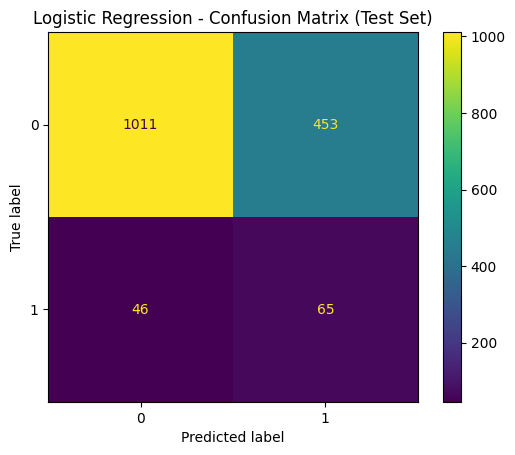

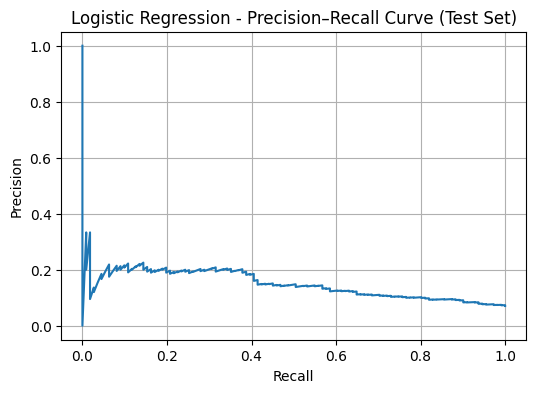


=== Logistic Regression (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.220787,0.034159
1,Balanced Accuracy,0.684099,0.011757
2,Macro F1,0.530194,0.005931


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

x = X.copy ()

# If both original and scaled columns exist, keep the scaled ones
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Try a few C values and choose the best one by validation PR AUC
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
scores = []

for C in C_values:

    clf = LogisticRegression (
        class_weight = "balanced",
        solver = "liblinear",
        max_iter = 5000,
        C = C
    )

    model = clf.fit (X_train, y_train)

    pred_train = model.predict (X_train)
    pred_val = model.predict (X_val)

    prob_train = model.predict_proba (X_train)[:, 1]
    prob_val = model.predict_proba (X_val)[:, 1]

    pr_train = average_precision_score (y_train, prob_train)
    pr_val = average_precision_score (y_val, prob_val)

    ba_train = balanced_accuracy_score (y_train, pred_train)
    ba_val = balanced_accuracy_score (y_val, pred_val)

    f1_train = f1_score (y_train, pred_train, average = "macro")
    f1_val = f1_score (y_val, pred_val, average = "macro")

    scores.append ({
        "C": C,
        "pr_train": pr_train,
        "pr_val": pr_val,
        "ba_train": ba_train,
        "ba_val": ba_val,
        "f1_train": f1_train,
        "f1_val": f1_val
    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df)

best_C = scores_df.loc[0, "C"]
print ()
print ("Best C:", best_C)

# Refit using train and validation together, then evaluate on test
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

final_clf = LogisticRegression (
    class_weight = "balanced",
    solver = "liblinear",
    max_iter = 5000,
    C = best_C
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Logistic Regression (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Logistic Regression - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Logistic Regression - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on train and validation for a more stable score
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== Logistic Regression (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results into model_results so we can compare models later
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Logistic Regression"] = {
    "model": "Logistic Regression",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test)
}


## Model 2: Decision Tree

A Decision Tree is a simple non-linear model.

We include it because it can learn non-linear rules and feature interactions, it does not need feature scaling, and it is fairly easy to explain at a high level.

A common issue with a single tree is overfitting, especially when there are many features. To reduce this, we tune the maximum depth and the minimum number of samples needed to split a node or stay in a leaf. We also keep the model reasonably simple and evaluate it on a separate test set.

Because defaults are rare, we use class weights so the tree pays more attention to the default class.

We report PR AUC (Average Precision) as the main metric, along with balanced accuracy and macro F1, since plain accuracy can be misleading on imbalanced data.

We tune hyperparameters on the validation set using PR AUC, run stratified 5-fold cross-validation on the train and validation data, and then show the test results with a confusion matrix and a small cross-validation summary table.

x shape: (7871, 105)
y shape: (7871,)

X_train: (4722, 105)
X_val  : (1574, 105)
X_test : (1575, 105)

Validation results (sorted by PR AUC):


,max_depth,min_samples_split,min_samples_leaf,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,3.0,2,1,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
1,3.0,2,2,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
2,3.0,2,5,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
3,3.0,5,1,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
4,3.0,5,2,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
5,3.0,5,5,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
6,3.0,10,1,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
7,3.0,10,2,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
8,3.0,10,5,0.153925,0.157190,0.684985,0.662288,0.450644,0.443187
9,5.0,2,5,0.204428,0.129224,0.729067,0.614925,0.546480,0.506347



Best parameters:
max_depth: 3
min_samples_split: 2
min_samples_leaf : 1

=== Decision Tree (Test Set) ===
PR AUC on test set: 0.12732001222294412
Balance Accuracy on test set: 0.6364643331856447
F1 Score on test set: 0.45723746993930603

Confusion Matrix (test set):
[[848 616]
 [ 34  77]]


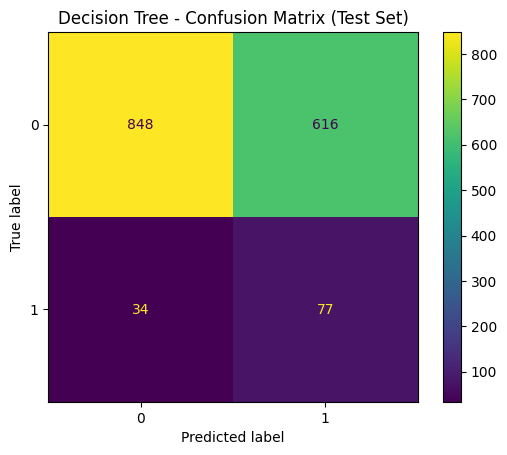

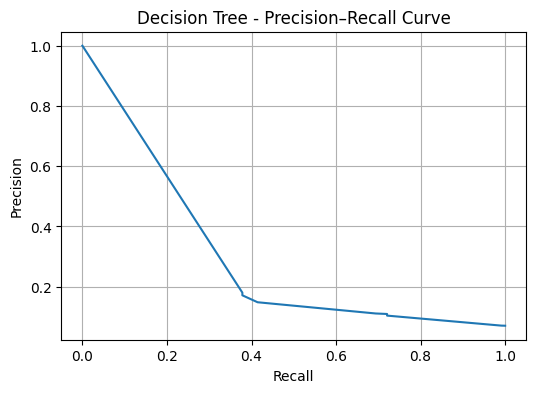


=== Decision Tree (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.137858,0.008787
1,Balanced Accuracy,0.667937,0.010841
2,Macro F1,0.457918,0.015391


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Feature matrix for Decision Tree
# Trees do not need scaling, so we use X as it is
x = X.copy ()

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Split into train, validation, and test sets (60, 20, 20)
# We stratify because the target is imbalanced
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Tune main tree settings using the validation set, using PR AUC
# We also track balanced accuracy and macro F1 for comparison
param_grid = []

max_depth_values = [3, 5, 7, 10, None]
min_samples_split_values = [2, 5, 10]
min_samples_leaf_values = [1, 2, 5]

for d in max_depth_values:
    for s in min_samples_split_values:
        for l in min_samples_leaf_values:
            param_grid.append ((d, s, l))

scores = []

for (d, s, l) in param_grid:

    clf = DecisionTreeClassifier (
        random_state = 42,
        class_weight = "balanced",
        max_depth = d,
        min_samples_split = s,
        min_samples_leaf = l
    )

    model = clf.fit (X_train, y_train)

    pred_train = model.predict (X_train)
    pred_val   = model.predict (X_val)

    prob_train = model.predict_proba (X_train)[:, 1]
    prob_val   = model.predict_proba (X_val)[:, 1]

    pr_train = average_precision_score (y_train, prob_train)
    pr_val   = average_precision_score (y_val, prob_val)

    ba_train = balanced_accuracy_score (y_train, pred_train)
    ba_val   = balanced_accuracy_score (y_val, pred_val)

    f1_train = f1_score (y_train, pred_train, average = "macro")
    f1_val   = f1_score (y_val, pred_val, average = "macro")

    scores.append ({
        "max_depth": d,
        "min_samples_split": s,
        "min_samples_leaf": l,
        "pr_train": pr_train,
        "pr_val": pr_val,
        "ba_train": ba_train,
        "ba_val": ba_val,
        "f1_train": f1_train,
        "f1_val": f1_val
    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (15))

best_max_depth = param_int_or_none (scores_df.loc[0, "max_depth"])
best_min_samples_split = param_int (scores_df.loc[0, "min_samples_split"])
best_min_samples_leaf  = param_int (scores_df.loc[0, "min_samples_leaf"])

print ()
print ("Best parameters:")
print ("max_depth:", best_max_depth)
print ("min_samples_split:", best_min_samples_split)
print ("min_samples_leaf :", best_min_samples_leaf)

# Final model trained on train and validation, then tested on the test set
final_clf = DecisionTreeClassifier (
    random_state = 42,
    class_weight = "balanced",
    max_depth = best_max_depth,
    min_samples_split = best_min_samples_split,
    min_samples_leaf = best_min_samples_leaf
)

final_model = final_clf.fit (
    pd.concat ([X_train, X_val], axis = 0),
    pd.concat ([y_train, y_val], axis = 0)
)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Decision Tree (Test Set) ===")
print ("PR AUC on test set:", pr_test)
print ("Balance Accuracy on test set:", ba_test)
print ("F1 Score on test set:", f1_test)

print ()
print ("Confusion Matrix (test set):")
print (confusion_matrix (y_test, pred_test))

labels = [0, 1]

disp = ConfusionMatrixDisplay (
    confusion_matrix = confusion_matrix (y_test, pred_test, labels = labels),
    display_labels = labels
)

disp.plot ()
plt.title ("Decision Tree - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve for the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Decision Tree - Precision–Recall Curve")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on train and validation only
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== Decision Tree (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final model comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Decision Tree"] = {
    "model": "Decision Tree",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "max_depth": best_max_depth,
    "min_samples_split": best_min_samples_split,
    "min_samples_leaf": best_min_samples_leaf
}


## Model 3: Random Forest

Random Forest is a strong “classic” model for tabular data. It usually works well because it averages many trees, so it is more stable than a single Decision Tree.

Because the target is imbalanced (few defaults), plain accuracy is not useful here. We focus mainly on PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more robust score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different values for the number of trees, the maximum tree depth, the minimum samples needed to split a node, the minimum samples allowed in a leaf, and how many features the model can consider at each split.


x shape: (7871, 105)
y shape: (7871,)

X_train: (4722, 105)
X_val  : (1574, 105)
X_test : (1575, 105)

Validation results (sorted by PR AUC):


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,200,10.0,10,5,sqrt,0.943714,0.265970,0.959463,0.589933,0.917260,0.610664
1,200,10.0,2,5,sqrt,0.943714,0.265970,0.959463,0.589933,0.917260,0.610664
2,200,NaN,2,5,sqrt,0.999266,0.257986,0.995395,0.533985,0.996769,0.545972
3,200,NaN,10,5,sqrt,0.999266,0.257986,0.995395,0.533985,0.996769,0.545972
4,200,10.0,10,1,sqrt,0.946319,0.255874,0.968771,0.580924,0.931707,0.600252
5,200,10.0,2,1,sqrt,0.958040,0.245439,0.978779,0.579495,0.942626,0.603028
6,200,NaN,10,1,sqrt,1.000000,0.236092,0.998503,0.504505,0.999193,0.490813
7,200,NaN,2,1,sqrt,1.000000,0.229395,1.000000,0.504505,1.000000,0.490813



Best parameters:
n_estimators: 200
max_depth: 10
min_samples_split: 10
min_samples_leaf : 5
max_features: sqrt

=== Random Forest (Test Set) ===
PR AUC (Average Precision) on test set: 0.16884448501428592
Balanced Accuracy on test set: 0.588770122581598
Macro F1 on test set: 0.589512876202296

Confusion Matrix (test set):
[[1381   83]
 [  85   26]]


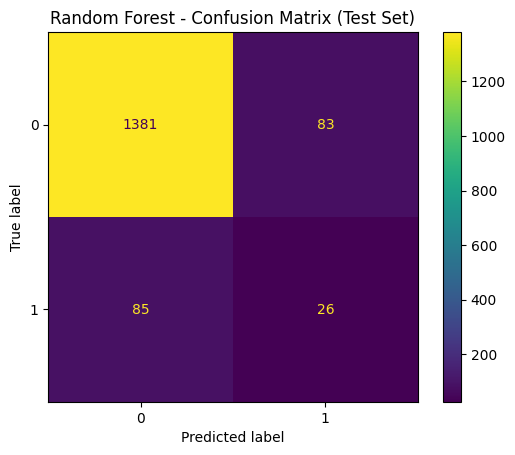

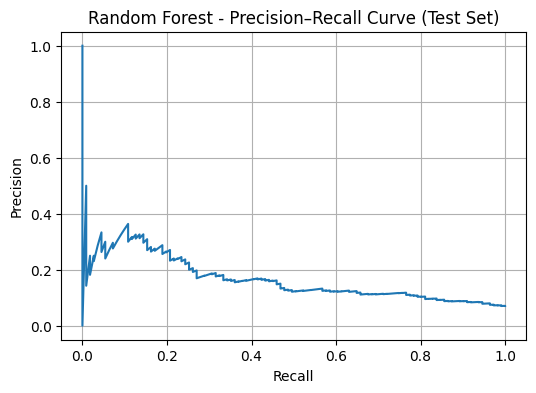


=== Random Forest (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.212925,0.025418
1,Balanced Accuracy,0.587197,0.014431
2,Macro F1,0.595913,0.014826


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Feature matrix for Random Forest
x = X.copy ()

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Small grid of settings to try, chosen using validation PR AUC
n_estimators_values = [200]
max_depth_values = [None, 10]
min_samples_split_values = [2, 10]
min_samples_leaf_values = [1, 5]
max_features_values = ["sqrt"]

scores = []

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for min_samples_split in min_samples_split_values:
            for min_samples_leaf in min_samples_leaf_values:
                for max_features in max_features_values:

                    clf = RandomForestClassifier (
                        n_estimators = n_estimators,
                        max_depth = max_depth,
                        min_samples_split = min_samples_split,
                        min_samples_leaf = min_samples_leaf,
                        max_features = max_features,
                        class_weight = "balanced_subsample",
                        random_state = 42,
                        n_jobs = -1
                    )

                    model = clf.fit (X_train, y_train)

                    pred_train = model.predict (X_train)
                    pred_val = model.predict (X_val)

                    prob_train = model.predict_proba (X_train)[:, 1]
                    prob_val = model.predict_proba (X_val)[:, 1]

                    pr_train = average_precision_score (y_train, prob_train)
                    pr_val = average_precision_score (y_val, prob_val)

                    ba_train = balanced_accuracy_score (y_train, pred_train)
                    ba_val = balanced_accuracy_score (y_val, pred_val)

                    f1_train = f1_score (y_train, pred_train, average = "macro")
                    f1_val = f1_score (y_val, pred_val, average = "macro")

                    scores.append ({
                        "n_estimators": n_estimators,
                        "max_depth": max_depth,
                        "min_samples_split": min_samples_split,
                        "min_samples_leaf": min_samples_leaf,
                        "max_features": max_features,
                        "pr_train": pr_train,
                        "pr_val": pr_val,
                        "ba_train": ba_train,
                        "ba_val": ba_val,
                        "f1_train": f1_train,
                        "f1_val": f1_val
                    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (20))

# Best settings from the validation ranking
best_n_estimators = int (scores_df.loc[0, "n_estimators"])

best_max_depth_raw = scores_df.loc[0, "max_depth"]
best_max_depth = None if pd.isna (best_max_depth_raw) else int (best_max_depth_raw)

best_min_samples_split = int (scores_df.loc[0, "min_samples_split"])
best_min_samples_leaf = int (scores_df.loc[0, "min_samples_leaf"])

best_max_features = scores_df.loc[0, "max_features"]
best_max_features = float (best_max_features) if isinstance (best_max_features, (int, float, np.number)) else str (best_max_features)

print ()
print ("Best parameters:")
print ("n_estimators:", best_n_estimators)
print ("max_depth:", best_max_depth)
print ("min_samples_split:", best_min_samples_split)
print ("min_samples_leaf :", best_min_samples_leaf)
print ("max_features:", best_max_features)

# Train final model on training and validation, then test on the test set
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

final_clf = RandomForestClassifier (
    n_estimators = best_n_estimators,
    max_depth = best_max_depth,
    min_samples_split = best_min_samples_split,
    min_samples_leaf = best_min_samples_leaf,
    max_features = best_max_features,
    class_weight = "balanced_subsample",
    random_state = 42,
    n_jobs = -1
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Random Forest (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Random Forest - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Random Forest - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation for a steadier estimate
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== Random Forest (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Random Forest"] = {
    "model": "Random Forest",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "n_estimators": best_n_estimators,
    "max_depth": best_max_depth,
    "min_samples_split": best_min_samples_split,
    "min_samples_leaf": best_min_samples_leaf,
    "max_features": best_max_features
}


## Model 4: k-Nearest Neighbours

k-Nearest Neighbours is a simple model that predicts using the most similar training samples. It can work well when the data has clear patterns, but it can struggle if we have many features or noise.

Because defaults are rare, we do not rely on plain accuracy. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different numbers of neighbours, different ways to weight neighbours, and different distance settings.


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,n_neighbors,weights,p,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,3,distance,2,1.000000,0.104979,1.000000,0.521559,1.000000,0.525046
1,11,distance,1,1.000000,0.099335,1.000000,0.500000,1.000000,0.481725
2,15,distance,1,1.000000,0.099149,1.000000,0.500000,1.000000,0.481725
3,15,distance,2,1.000000,0.095306,1.000000,0.500000,1.000000,0.481725
4,5,distance,2,1.000000,0.093219,1.000000,0.502112,1.000000,0.489090
5,3,distance,1,1.000000,0.092059,1.000000,0.510499,1.000000,0.507776
6,3,uniform,2,0.454070,0.090504,0.590308,0.521559,0.632039,0.525046
7,11,distance,2,1.000000,0.090453,1.000000,0.500000,1.000000,0.481725
8,15,uniform,2,0.220402,0.090212,0.500000,0.500000,0.481668,0.481725
9,15,uniform,1,0.225942,0.090098,0.499886,0.500000,0.481612,0.481725



Best parameters:
n_neighbors: 3
weights: distance
p: 2

=== k-Nearest Neighbours (Test Set) ===
PR AUC (Average Precision) on test set: 0.07409516774362314
Balanced Accuracy on test set: 0.4994461674789544
Macro F1 on test set: 0.4914193589444433

Confusion Matrix (test set):
[[1436   28]
 [ 109    2]]


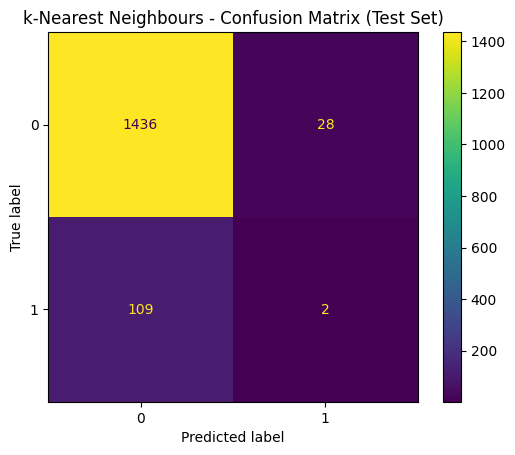

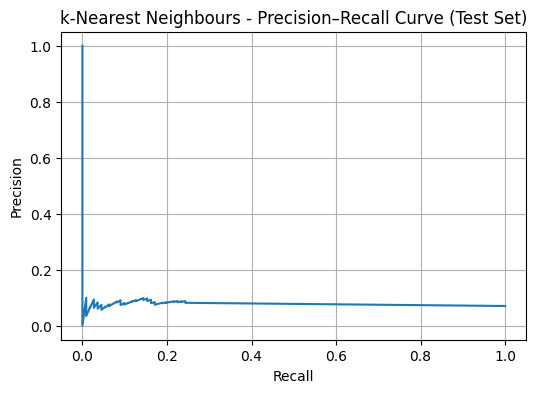


=== k-Nearest Neighbours (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.099428,0.010298
1,Balanced Accuracy,0.517272,0.011844
2,Macro F1,0.517582,0.018808


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Try a small set of k values and distance options, choose using validation PR AUC
n_neighbors_values = [3, 5, 7, 11, 15]
weights_values = ["uniform", "distance"]
p_values = [1, 2]

scores = []

for n_neighbors in n_neighbors_values:
    for weights in weights_values:
        for p in p_values:

            clf = KNeighborsClassifier (
                n_neighbors = n_neighbors,
                weights = weights,
                p = p,
                metric = "minkowski",
                n_jobs = -1
            )

            model = clf.fit (X_train, y_train)

            pred_train = model.predict (X_train)
            pred_val = model.predict (X_val)

            prob_train = model.predict_proba (X_train)[:, 1]
            prob_val = model.predict_proba (X_val)[:, 1]

            pr_train = average_precision_score (y_train, prob_train)
            pr_val = average_precision_score (y_val, prob_val)

            ba_train = balanced_accuracy_score (y_train, pred_train)
            ba_val = balanced_accuracy_score (y_val, pred_val)

            f1_train = f1_score (y_train, pred_train, average = "macro")
            f1_val = f1_score (y_val, pred_val, average = "macro")

            scores.append ({
                "n_neighbors": n_neighbors,
                "weights": weights,
                "p": p,
                "pr_train": pr_train,
                "pr_val": pr_val,
                "ba_train": ba_train,
                "ba_val": ba_val,
                "f1_train": f1_train,
                "f1_val": f1_val
            })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df)

best_n_neighbors = int (scores_df.loc[0, "n_neighbors"])
best_weights = str (scores_df.loc[0, "weights"])
best_p = int (scores_df.loc[0, "p"])

print ()
print ("Best parameters:")
print ("n_neighbors:", best_n_neighbors)
print ("weights:", best_weights)
print ("p:", best_p)

# Train final model on training and validation, then test on the test set
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

final_clf = KNeighborsClassifier (
    n_neighbors = best_n_neighbors,
    weights = best_weights,
    p = best_p,
    metric = "minkowski",
    n_jobs = -1
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== k-Nearest Neighbours (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("k-Nearest Neighbours - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("k-Nearest Neighbours - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation for a steadier estimate
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== k-Nearest Neighbours (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["k-Nearest Neighbours"] = {
    "model": "k-Nearest Neighbours",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "n_neighbors": best_n_neighbors,
    "weights": best_weights,
    "p": best_p
}


## Model 5: Naive Bayes

Naive Bayes is a very fast baseline. It makes strong independence assumptions, so it is not always the best model, but it is a good reference point and it gives us results quickly.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different values for the smoothing setting that stabilises the variance estimate.


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,var_smoothing,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,1.000000e-08,0.145753,0.137045,0.657749,0.659499,0.486852,0.487786
1,1.000000e-12,0.145752,0.137009,0.657749,0.659499,0.486852,0.487786
2,1.000000e-11,0.145752,0.137009,0.657749,0.659499,0.486852,0.487786
3,1.000000e-10,0.145752,0.137009,0.657749,0.659499,0.486852,0.487786
4,1.000000e-09,0.145752,0.137009,0.657749,0.659499,0.486852,0.487786



Best var_smoothing: 1e-08

=== Naive Bayes (Test Set) ===
PR AUC (Average Precision) on test set: 0.09316687815958119
Balanced Accuracy on test set: 0.5301931029390046
Macro F1 on test set: 0.25533638395514

Confusion Matrix (test set):
[[ 339 1125]
 [  19   92]]


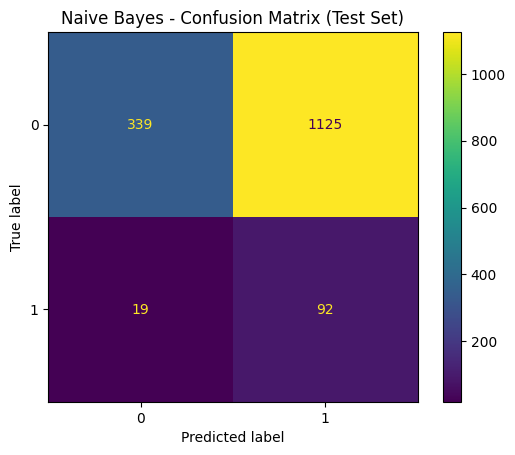

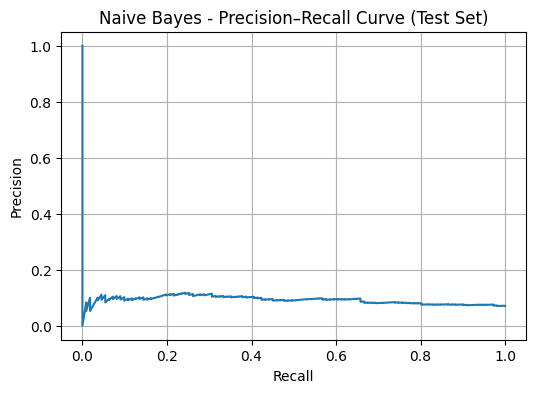


=== Naive Bayes (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.124086,0.009220
1,Balanced Accuracy,0.531463,0.021165
2,Macro F1,0.173803,0.044846


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

# GaussianNB expects a dense array, so convert if needed
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Try a few smoothing values, choose using validation PR AUC
var_smoothing_values = [1e-12, 1e-11, 1e-10, 1e-9, 1e-8]
scores = []

for var_smoothing in var_smoothing_values:

    clf = GaussianNB (
        var_smoothing = var_smoothing
    )

    model = clf.fit (X_train, y_train)

    pred_train = model.predict (X_train)
    pred_val = model.predict (X_val)

    prob_train = model.predict_proba (X_train)[:, 1]
    prob_val = model.predict_proba (X_val)[:, 1]

    pr_train = average_precision_score (y_train, prob_train)
    pr_val = average_precision_score (y_val, prob_val)

    ba_train = balanced_accuracy_score (y_train, pred_train)
    ba_val = balanced_accuracy_score (y_val, pred_val)

    f1_train = f1_score (y_train, pred_train, average = "macro")
    f1_val = f1_score (y_val, pred_val, average = "macro")

    scores.append ({
        "var_smoothing": var_smoothing,
        "pr_train": pr_train,
        "pr_val": pr_val,
        "ba_train": ba_train,
        "ba_val": ba_val,
        "f1_train": f1_train,
        "f1_val": f1_val
    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df)

best_var_smoothing = float (scores_df.loc[0, "var_smoothing"])

print ()
print ("Best var_smoothing:", best_var_smoothing)

# Train final model on training and validation, then test on the test set
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

final_clf = GaussianNB (
    var_smoothing = best_var_smoothing
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Naive Bayes (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Naive Bayes - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Naive Bayes - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation for a steadier estimate
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== Naive Bayes (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Naive Bayes"] = {
    "model": "Naive Bayes",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "var_smoothing": best_var_smoothing
}


## Model 6: Linear SVM

A linear SVM is a strong model for high-dimensional tabular data, especially after one-hot encoding. It often works well, but it needs good scaling and it can be sensitive to the regularisation strength.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the regularisation strength on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different values of the regularisation strength C.


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,C,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,0.01,0.232416,0.280197,0.712176,0.702281,0.537315,0.535956
1,0.10,0.229993,0.276790,0.710239,0.689171,0.534824,0.527579
2,1.00,0.227972,0.261872,0.713005,0.671898,0.535564,0.518199
3,10.00,0.227299,0.258672,0.716568,0.671898,0.537331,0.518199



Best C: 0.01

=== Linear SVM (Test Set) ===
PR AUC (Average Precision) on test set: 0.1516491701566713
Balanced Accuracy on test set: 0.6384212080933392
Macro F1 on test set: 0.5047720189719008

Confusion Matrix (test set):
[[1012  452]
 [  46   65]]


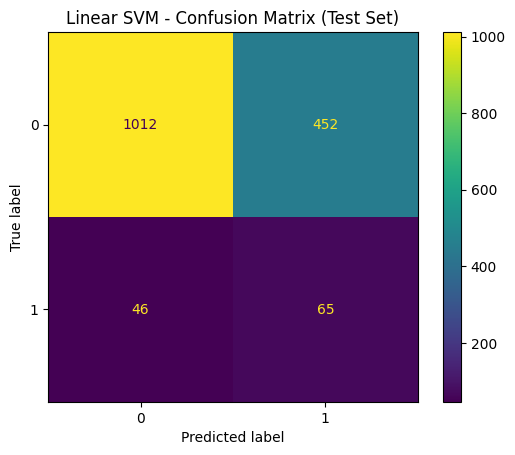

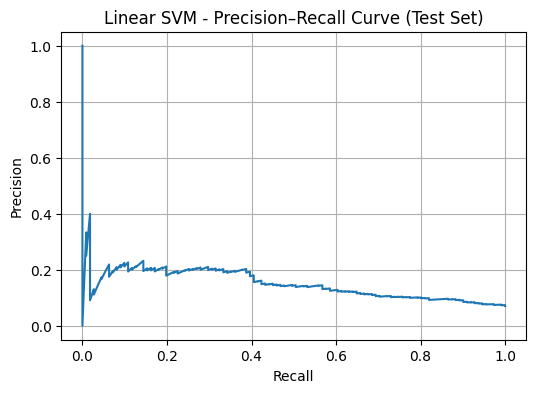


=== Linear SVM (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.221918,0.034482
1,Balanced Accuracy,0.685662,0.012821
2,Macro F1,0.530131,0.005562


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Try a few C values and choose the best one by validation PR AUC
C_values = [0.01, 0.1, 1.0, 10.0]
scores = []

for C in C_values:

    clf = LinearSVC (
        C = C,
        class_weight = "balanced",
        dual = "auto",
        max_iter = 20000,
        random_state = 42
    )

    model = clf.fit (X_train, y_train)

    pred_train = model.predict (X_train)
    pred_val = model.predict (X_val)

    # LinearSVC gives a decision score instead of probabilities
    score_train = model.decision_function (X_train)
    score_val = model.decision_function (X_val)

    pr_train = average_precision_score (y_train, score_train)
    pr_val = average_precision_score (y_val, score_val)

    ba_train = balanced_accuracy_score (y_train, pred_train)
    ba_val = balanced_accuracy_score (y_val, pred_val)

    f1_train = f1_score (y_train, pred_train, average = "macro")
    f1_val = f1_score (y_val, pred_val, average = "macro")

    scores.append ({
        "C": C,
        "pr_train": pr_train,
        "pr_val": pr_val,
        "ba_train": ba_train,
        "ba_val": ba_val,
        "f1_train": f1_train,
        "f1_val": f1_val
    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df)

best_C = float (scores_df.loc[0, "C"])

print ()
print ("Best C:", best_C)

# Train final model on training and validation, then test on the test set
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

final_clf = LinearSVC (
    C = best_C,
    class_weight = "balanced",
    dual = "auto",
    max_iter = 20000,
    random_state = 42
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
score_test = final_model.decision_function (X_test)

pr_test = average_precision_score (y_test, score_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Linear SVM (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Linear SVM - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, score_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Linear SVM - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation for a steadier estimate
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== Linear SVM (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Linear SVM"] = {
    "model": "Linear SVM",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "C": float (best_C)
}


## Model 7: Histogram Gradient Boosting

This model is usually strong on tabular data because it builds many small trees and learns step by step. It can handle non-linear patterns and feature interactions well.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different learning rates, different maximum tree depths, different numbers of leaf nodes, different minimum samples per leaf, and different L2 regularisation strengths.


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,learning_rate,max_depth,max_leaf_nodes,min_samples_leaf,l2_regularization,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,0.05,NaN,31,20,0.0,1.000000,0.246205,0.999544,0.585429,0.996796,0.605487
1,0.10,NaN,63,50,0.1,1.000000,0.233895,1.000000,0.549611,1.000000,0.569643
2,0.05,NaN,63,50,0.0,1.000000,0.231315,1.000000,0.551040,1.000000,0.569054
3,0.05,NaN,31,50,0.0,1.000000,0.230647,0.998861,0.582694,0.992055,0.598460
4,0.10,6.0,31,50,0.1,1.000000,0.227795,0.998974,0.586515,0.992840,0.601721
5,0.10,NaN,63,50,0.0,1.000000,0.222644,1.000000,0.531251,1.000000,0.540747
6,0.05,NaN,63,50,0.1,1.000000,0.219024,1.000000,0.545168,1.000000,0.559697
7,0.05,NaN,31,20,0.1,1.000000,0.218590,0.999316,0.576420,0.995207,0.594957
8,0.10,NaN,31,50,0.1,1.000000,0.218187,1.000000,0.560391,1.000000,0.582547
9,0.10,6.0,31,50,0.0,1.000000,0.217302,0.999316,0.580986,0.995207,0.594309



Best parameters:
learning_rate: 0.05
max_depth: None
max_leaf_nodes: 31
min_samples_leaf: 20
l2_regularization: 0.0

=== Histogram Gradient Boosting (Test Set) ===
PR AUC (Average Precision) on test set: 0.15447807929711577
Balanced Accuracy on test set: 0.5431897060995422
Macro F1 on test set: 0.5529378370706783

Confusion Matrix (test set):
[[1419   45]
 [  98   13]]


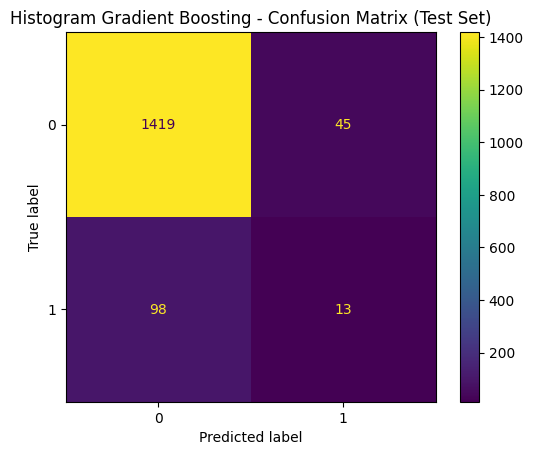

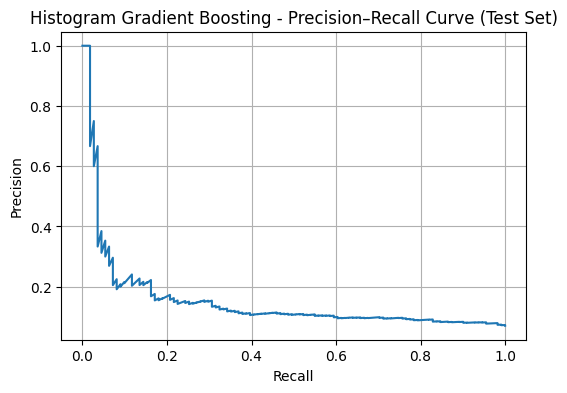


=== Histogram Gradient Boosting (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.191064,0.040129
1,Balanced Accuracy,0.542725,0.016282
2,Macro F1,0.554611,0.021606


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

# Convert to dense if we get a sparse matrix
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Sample weights to handle class imbalance
sample_weight_train = compute_sample_weight (class_weight = "balanced", y = y_train)

# Small grid of settings to try, chosen using validation PR AUC
learning_rate_values = [0.05, 0.1]
max_depth_values = [None, 6]
max_leaf_nodes_values = [31, 63]
min_samples_leaf_values = [20, 50]
l2_regularization_values = [0.0, 0.1]

scores = []

for learning_rate in learning_rate_values:
    for max_depth in max_depth_values:
        for max_leaf_nodes in max_leaf_nodes_values:
            for min_samples_leaf in min_samples_leaf_values:
                for l2_regularization in l2_regularization_values:

                    clf = HistGradientBoostingClassifier (
                        learning_rate = learning_rate,
                        max_iter = 300,
                        max_depth = max_depth,
                        max_leaf_nodes = max_leaf_nodes,
                        min_samples_leaf = min_samples_leaf,
                        l2_regularization = l2_regularization,
                        random_state = 42,
                        early_stopping = False
                    )

                    model = clf.fit (X_train, y_train, sample_weight = sample_weight_train)

                    pred_train = model.predict (X_train)
                    pred_val = model.predict (X_val)

                    prob_train = model.predict_proba (X_train)[:, 1]
                    prob_val = model.predict_proba (X_val)[:, 1]

                    pr_train = average_precision_score (y_train, prob_train)
                    pr_val = average_precision_score (y_val, prob_val)

                    ba_train = balanced_accuracy_score (y_train, pred_train)
                    ba_val = balanced_accuracy_score (y_val, pred_val)

                    f1_train = f1_score (y_train, pred_train, average = "macro")
                    f1_val = f1_score (y_val, pred_val, average = "macro")

                    scores.append ({
                        "learning_rate": learning_rate,
                        "max_depth": max_depth,
                        "max_leaf_nodes": max_leaf_nodes,
                        "min_samples_leaf": min_samples_leaf,
                        "l2_regularization": l2_regularization,
                        "pr_train": pr_train,
                        "pr_val": pr_val,
                        "ba_train": ba_train,
                        "ba_val": ba_val,
                        "f1_train": f1_train,
                        "f1_val": f1_val
                    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (20))

best_learning_rate = float (scores_df.loc[0, "learning_rate"])

best_max_depth_raw = scores_df.loc[0, "max_depth"]
best_max_depth = None if pd.isna (best_max_depth_raw) else int (best_max_depth_raw)

best_max_leaf_nodes = int (scores_df.loc[0, "max_leaf_nodes"])
best_min_samples_leaf = int (scores_df.loc[0, "min_samples_leaf"])
best_l2_regularization = float (scores_df.loc[0, "l2_regularization"])

print ()
print ("Best parameters:")
print ("learning_rate:", best_learning_rate)
print ("max_depth:", best_max_depth)
print ("max_leaf_nodes:", best_max_leaf_nodes)
print ("min_samples_leaf:", best_min_samples_leaf)
print ("l2_regularization:", best_l2_regularization)

# Train final model on training and validation, then test on the test set
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

sample_weight_trainval = compute_sample_weight (class_weight = "balanced", y = y_trainval)

final_clf = HistGradientBoostingClassifier (
    learning_rate = best_learning_rate,
    max_iter = 500,
    max_depth = best_max_depth,
    max_leaf_nodes = best_max_leaf_nodes,
    min_samples_leaf = best_min_samples_leaf,
    l2_regularization = best_l2_regularization,
    random_state = 42,
    early_stopping = False
)

final_model = final_clf.fit (X_trainval, y_trainval, sample_weight = sample_weight_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== Histogram Gradient Boosting (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Histogram Gradient Boosting - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Histogram Gradient Boosting - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

def take_rows (a, idx):
    # Works for both pandas and numpy style indexing
    if hasattr (a, "iloc"):
        return a.iloc[idx]
    return a[idx]

# Manual 5-fold stratified CV using sample weights inside each fold
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval, y_trainval):

    X_tr = take_rows (X_trainval, train_index)
    y_tr = take_rows (y_trainval, train_index)

    X_va = take_rows (X_trainval, valid_index)
    y_va = take_rows (y_trainval, valid_index)

    w_tr = compute_sample_weight (class_weight = "balanced", y = y_tr)

    fold_clf = HistGradientBoostingClassifier (**final_clf.get_params ())
    fold_model = fold_clf.fit (X_tr, y_tr, sample_weight = w_tr)

    pred_va = fold_model.predict (X_va)
    prob_va = fold_model.predict_proba (X_va)[:, 1]

    pr_scores.append (average_precision_score (y_va, prob_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (pr_scores)),
        float (np.mean (ba_scores)),
        float (np.mean (f1_scores))
    ],
    "std": [
        float (np.std (pr_scores)),
        float (np.std (ba_scores)),
        float (np.std (f1_scores))
    ]
})

print ()
print ("=== Histogram Gradient Boosting (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Histogram Gradient Boosting"] = {
    "model": "Histogram Gradient Boosting",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "learning_rate": best_learning_rate,
    "max_iter": 500,
    "max_depth": best_max_depth,
    "max_leaf_nodes": best_max_leaf_nodes,
    "min_samples_leaf": best_min_samples_leaf,
    "l2_regularization": best_l2_regularization
}


## Model 8: XGBoost

XGBoost is usually one of the best choices for tabular data. It builds trees step by step and corrects its own mistakes, so it can learn complex patterns without needing manual feature engineering.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different learning rates, different tree depths, different subsampling levels, different feature sampling levels, and different minimum child weights. We also let the model stop early if the validation score stops improving.


## WARNING!!!

If you want to run the next XGBoost model, install the package once in the code cell below:

`!pip -q install xgboost` (around 400 MB)

If you do not want to install extra packages, you can simply skip the XGBoost model section.

In [ ]:
!pip -q install xgboost

x shape: (7871, 105)
y shape: (7871,)

X_train: (4722, 105)
X_val  : (1574, 105)
X_test : (1575, 105)

scale_pos_weight: 13.137724550898204

Validation results (sorted by PR AUC):


,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,400,0.05,3,0.8,1.0,5,0.735355,0.249975,0.923157,0.670106,0.736232,0.593546
1,400,0.05,3,0.8,0.8,1,0.752154,0.247269,0.929797,0.663893,0.747027,0.588291
2,400,0.05,3,0.8,0.8,5,0.754701,0.245634,0.926834,0.662122,0.739305,0.590371
3,400,0.05,3,0.8,1.0,1,0.765301,0.239088,0.922913,0.659668,0.738768,0.591320
4,400,0.05,5,0.8,1.0,1,0.999891,0.224435,0.996696,0.584465,0.977539,0.596712
5,400,0.10,3,0.8,1.0,1,0.954617,0.224341,0.970130,0.619783,0.848880,0.598257
6,400,0.10,3,0.8,1.0,5,0.950659,0.223320,0.969690,0.630563,0.841973,0.602708
7,400,0.05,5,0.8,0.8,1,0.999991,0.220219,0.996696,0.595866,0.977539,0.612354
8,800,0.05,5,0.8,1.0,1,1.000000,0.217652,1.000000,0.553835,1.000000,0.571411
9,800,0.10,5,0.8,1.0,5,1.000000,0.216761,1.000000,0.553152,1.000000,0.569867



Best parameters:
n_estimators: 400
learning_rate: 0.05
max_depth: 3
subsample: 0.8
colsample_bytree: 1.0
min_child_weight: 5.0

=== XGBoost (Test Set) ===
PR AUC (Average Precision) on test set: 0.14020099699067057
Balanced Accuracy on test set: 0.6195632107517354
Macro F1 on test set: 0.5447124992480801

Confusion Matrix (test set):
[[1181  283]
 [  63   48]]


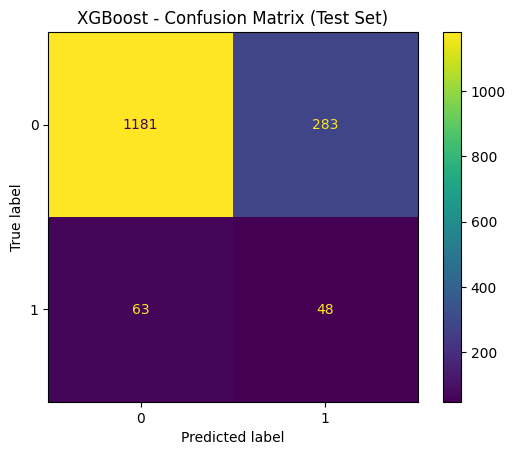

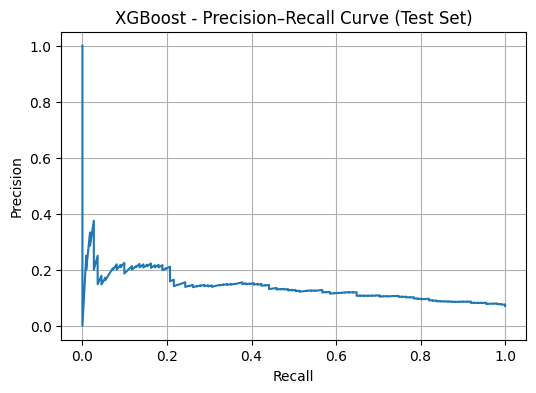


=== XGBoost (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.198011,0.014241
1,Balanced Accuracy,0.661698,0.013504
2,Macro F1,0.579506,0.007847


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

try:
    from xgboost import XGBClassifier
except Exception as e:
    raise ImportError ("xgboost is required for Model 8. Install it and run again.") from e


def stack_rows (a, b):
    if hasattr (a, "iloc"):
        return pd.concat ([a, b], axis = 0)
    return np.vstack ([a, b])


def stack_y (a, b):
    if hasattr (a, "iloc"):
        return pd.concat ([a, b], axis = 0)
    return np.concatenate ([a, b])


x = X.copy ()

# Convert to dense if we get a sparse matrix
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Handle class imbalance using scale_pos_weight
pos_count = float (np.sum (y_train == 1))
neg_count = float (np.sum (y_train == 0))
scale_pos_weight = (neg_count / pos_count) if pos_count > 0 else 1.0

print ()
print ("scale_pos_weight:", scale_pos_weight)

# Small grid of settings to try, chosen using validation PR AUC
n_estimators_values = [400, 800]
learning_rate_values = [0.05, 0.1]
max_depth_values = [3, 5]
subsample_values = [0.8]
colsample_bytree_values = [0.8, 1.0]
min_child_weight_values = [1, 5]

scores = []

for n_estimators in n_estimators_values:
    for learning_rate in learning_rate_values:
        for max_depth in max_depth_values:
            for subsample in subsample_values:
                for colsample_bytree in colsample_bytree_values:
                    for min_child_weight in min_child_weight_values:

                        clf = XGBClassifier (
                            n_estimators = n_estimators,
                            learning_rate = learning_rate,
                            max_depth = max_depth,
                            subsample = subsample,
                            colsample_bytree = colsample_bytree,
                            min_child_weight = min_child_weight,
                            reg_lambda = 1.0,
                            objective = "binary:logistic",
                            eval_metric = "aucpr",
                            n_jobs = -1,
                            random_state = 42,
                            scale_pos_weight = scale_pos_weight
                        )

                        model = clf.fit (X_train, y_train)

                        pred_train = model.predict (X_train)
                        pred_val = model.predict (X_val)

                        prob_train = model.predict_proba (X_train)[:, 1]
                        prob_val = model.predict_proba (X_val)[:, 1]

                        pr_train = average_precision_score (y_train, prob_train)
                        pr_val = average_precision_score (y_val, prob_val)

                        ba_train = balanced_accuracy_score (y_train, pred_train)
                        ba_val = balanced_accuracy_score (y_val, pred_val)

                        f1_train = f1_score (y_train, pred_train, average = "macro")
                        f1_val = f1_score (y_val, pred_val, average = "macro")

                        scores.append ({
                            "n_estimators": n_estimators,
                            "learning_rate": learning_rate,
                            "max_depth": max_depth,
                            "subsample": subsample,
                            "colsample_bytree": colsample_bytree,
                            "min_child_weight": min_child_weight,
                            "pr_train": pr_train,
                            "pr_val": pr_val,
                            "ba_train": ba_train,
                            "ba_val": ba_val,
                            "f1_train": f1_train,
                            "f1_val": f1_val
                        })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (20))

best_n_estimators = int (scores_df.loc[0, "n_estimators"])
best_learning_rate = float (scores_df.loc[0, "learning_rate"])
best_max_depth = int (scores_df.loc[0, "max_depth"])
best_subsample = float (scores_df.loc[0, "subsample"])
best_colsample_bytree = float (scores_df.loc[0, "colsample_bytree"])
best_min_child_weight = float (scores_df.loc[0, "min_child_weight"])

print ()
print ("Best parameters:")
print ("n_estimators:", best_n_estimators)
print ("learning_rate:", best_learning_rate)
print ("max_depth:", best_max_depth)
print ("subsample:", best_subsample)
print ("colsample_bytree:", best_colsample_bytree)
print ("min_child_weight:", best_min_child_weight)

# Train final model on training and validation together
X_trainval = stack_rows (X_train, X_val)
y_trainval = stack_y (y_train, y_val)

pos_count_tv = float (np.sum (y_trainval == 1))
neg_count_tv = float (np.sum (y_trainval == 0))
scale_pos_weight_tv = (neg_count_tv / pos_count_tv) if pos_count_tv > 0 else 1.0

final_clf = XGBClassifier (
    n_estimators = best_n_estimators,
    learning_rate = best_learning_rate,
    max_depth = best_max_depth,
    subsample = best_subsample,
    colsample_bytree = best_colsample_bytree,
    min_child_weight = best_min_child_weight,
    reg_lambda = 1.0,
    objective = "binary:logistic",
    eval_metric = "aucpr",
    n_jobs = -1,
    random_state = 42,
    scale_pos_weight = scale_pos_weight_tv
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== XGBoost (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("XGBoost - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("XGBoost - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== XGBoost (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["XGBoost"] = {
    "model": "XGBoost",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "n_estimators": best_n_estimators,
    "learning_rate": best_learning_rate,
    "max_depth": best_max_depth,
    "subsample": best_subsample,
    "colsample_bytree": best_colsample_bytree,
    "min_child_weight": best_min_child_weight
}


## Model 9: LightGBM

LightGBM is usually a very strong model for tabular data. It builds trees step by step, so it can learn non-linear patterns and feature interactions.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different learning rates, different numbers of trees, different maximum tree depths, different numbers of leaves, and different minimum samples in a leaf.


## WARNING!!!

If you want to run the next LightGBM model, install the package once in the code cell below:

`!pip -q install xgboost` (around 5 MB)

If you do not want to install extra packages, you can simply skip the LightGBM model section.

In [25]:
!pip -q install lightgbm

x shape: (7871, 105)
y shape: (7871,)

X_train: (4722, 105)
X_val  : (1574, 105)
X_test : (1575, 105)

scale_pos_weight: 13.137724550898204

Validation results (sorted by PR AUC):


,learning_rate,n_estimators,max_depth,num_leaves,min_child_samples,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,0.10,400,-1,63,20,1.0,0.225216,1.000000,0.541286,1.000000,0.557190
1,0.10,800,-1,63,20,1.0,0.224929,1.000000,0.532960,1.000000,0.543957
2,0.05,400,-1,31,20,1.0,0.223984,1.000000,0.573221,1.000000,0.599062
3,0.10,400,8,31,50,1.0,0.222546,1.000000,0.558682,1.000000,0.578324
4,0.05,800,-1,31,20,1.0,0.222160,1.000000,0.548586,1.000000,0.567222
5,0.05,800,-1,63,50,1.0,0.220834,1.000000,0.549269,1.000000,0.568827
6,0.05,400,-1,63,50,1.0,0.219780,1.000000,0.552065,1.000000,0.571442
7,0.10,800,8,31,50,1.0,0.219762,1.000000,0.547561,1.000000,0.564880
8,0.10,400,8,31,20,1.0,0.218900,1.000000,0.551723,1.000000,0.570637
9,0.10,400,-1,63,50,1.0,0.216855,1.000000,0.525722,1.000000,0.531772



Best parameters:
learning_rate: 0.1
n_estimators: 400
max_depth: -1
num_leaves: 63
min_child_samples: 20

=== LightGBM (Test Set) ===
PR AUC (Average Precision) on test set: 0.1473757518384221
Balanced Accuracy on test set: 0.52156254615271
Macro F1 on test set: 0.5250597491408335

Confusion Matrix (test set):
[[1448   16]
 [ 105    6]]


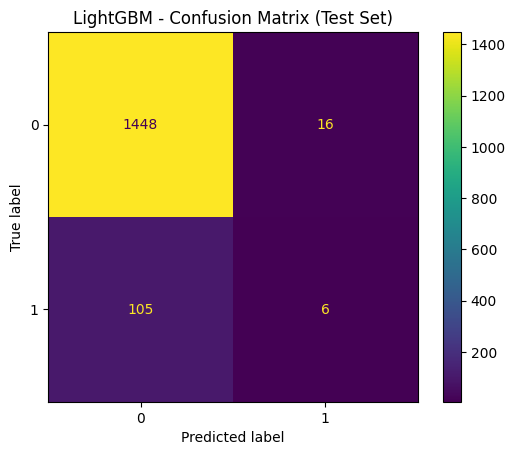

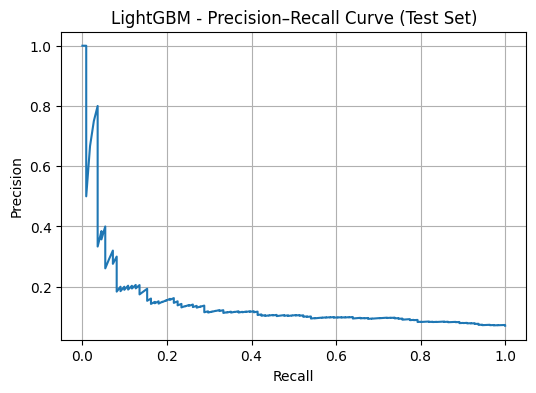


=== LightGBM (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.203915,0.039115
1,Balanced Accuracy,0.541196,0.013433
2,Macro F1,0.556152,0.020862


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

try:
    from lightgbm import LGBMClassifier
except Exception as e:
    raise ImportError ("lightgbm is required for Model 9. Install it and run again.") from e

x = X.copy ()

# Convert to dense if we get a sparse matrix
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Handle class imbalance using scale_pos_weight
pos_count = float (np.sum (y_train == 1))
neg_count = float (np.sum (y_train == 0))
scale_pos_weight = (neg_count / pos_count) if pos_count > 0 else 1.0

print ()
print ("scale_pos_weight:", scale_pos_weight)

# Small grid of settings to try, chosen using validation PR AUC
learning_rate_values = [0.05, 0.1]
n_estimators_values = [400, 800]
max_depth_values = [-1, 8]
num_leaves_values = [31, 63]
min_child_samples_values = [20, 50]

scores = []

for learning_rate in learning_rate_values:
    for n_estimators in n_estimators_values:
        for max_depth in max_depth_values:
            for num_leaves in num_leaves_values:
                for min_child_samples in min_child_samples_values:

                    clf = LGBMClassifier (
                        objective = "binary",
                        learning_rate = learning_rate,
                        n_estimators = n_estimators,
                        max_depth = max_depth,
                        num_leaves = num_leaves,
                        min_child_samples = min_child_samples,
                        subsample = 0.8,
                        colsample_bytree = 0.8,
                        reg_lambda = 1.0,
                        random_state = 42,
                        n_jobs = -1,
                        scale_pos_weight = scale_pos_weight,
                        verbosity = -1
                    )

                    model = clf.fit (X_train, y_train)

                    pred_train = model.predict (X_train)
                    pred_val = model.predict (X_val)

                    prob_train = model.predict_proba (X_train)[:, 1]
                    prob_val = model.predict_proba (X_val)[:, 1]

                    pr_train = average_precision_score (y_train, prob_train)
                    pr_val = average_precision_score (y_val, prob_val)

                    ba_train = balanced_accuracy_score (y_train, pred_train)
                    ba_val = balanced_accuracy_score (y_val, pred_val)

                    f1_train = f1_score (y_train, pred_train, average = "macro")
                    f1_val = f1_score (y_val, pred_val, average = "macro")

                    scores.append ({
                        "learning_rate": learning_rate,
                        "n_estimators": n_estimators,
                        "max_depth": max_depth,
                        "num_leaves": num_leaves,
                        "min_child_samples": min_child_samples,
                        "pr_train": pr_train,
                        "pr_val": pr_val,
                        "ba_train": ba_train,
                        "ba_val": ba_val,
                        "f1_train": f1_train,
                        "f1_val": f1_val
                    })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (20))

best_learning_rate = float (scores_df.loc[0, "learning_rate"])
best_n_estimators = int (scores_df.loc[0, "n_estimators"])
best_max_depth = int (scores_df.loc[0, "max_depth"])
best_num_leaves = int (scores_df.loc[0, "num_leaves"])
best_min_child_samples = int (scores_df.loc[0, "min_child_samples"])

print ()
print ("Best parameters:")
print ("learning_rate:", best_learning_rate)
print ("n_estimators:", best_n_estimators)
print ("max_depth:", best_max_depth)
print ("num_leaves:", best_num_leaves)
print ("min_child_samples:", best_min_child_samples)

# Train final model on training and validation together
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

pos_count_tv = float (np.sum (y_trainval == 1))
neg_count_tv = float (np.sum (y_trainval == 0))
scale_pos_weight_tv = (neg_count_tv / pos_count_tv) if pos_count_tv > 0 else 1.0

final_clf = LGBMClassifier (
    objective = "binary",
    learning_rate = best_learning_rate,
    n_estimators = best_n_estimators,
    max_depth = best_max_depth,
    num_leaves = best_num_leaves,
    min_child_samples = best_min_child_samples,
    subsample = 0.8,
    colsample_bytree = 0.8,
    reg_lambda = 1.0,
    random_state = 42,
    n_jobs = -1,
    scale_pos_weight = scale_pos_weight_tv,
    verbosity = -1
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== LightGBM (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("LightGBM - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("LightGBM - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== LightGBM (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["LightGBM"] = {
    "model": "LightGBM",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "learning_rate": best_learning_rate,
    "n_estimators": best_n_estimators,
    "max_depth": best_max_depth,
    "num_leaves": best_num_leaves,
    "min_child_samples": best_min_child_samples,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "scale_pos_weight": float (scale_pos_weight_tv)
}


## Model 10: CatBoost

CatBoost is another strong boosting model for tabular data. It often performs very well and is usually quite stable. It can also handle categorical features nicely, but here we already encoded the data, so we use it like a normal tabular model.

Because defaults are rare, we mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the model on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a stable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different learning rates, different tree depths, different numbers of iterations, and different L2 regularisation strengths.


## WARNING!!!

If you want to run the next CatBoost model, install the package once in the code cell below:

`!pip install -q catboost` (around 100 MB)

If you do not want to install extra packages, you can simply skip the CatBoost model section.

In [27]:
!pip -q install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 5.8 MB/s eta 0:00:00


x shape: (7871, 105)
y shape: (7871,)

X_train: (4722, 105)
X_val  : (1574, 105)
X_test : (1575, 105)

class_weights: [1.0, 13.137724550898204]

Validation results (sorted by PR AUC):


,learning_rate,depth,iterations,l2_leaf_reg,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,0.03,4,500,1.0,0.715985,0.291389,0.911943,0.667714,0.717810,0.589571
1,0.03,4,1000,10.0,0.919996,0.291112,0.961356,0.624069,0.816001,0.590404
2,0.03,4,500,3.0,0.675839,0.285077,0.900029,0.699307,0.701691,0.600711
3,0.03,4,500,10.0,0.602299,0.284095,0.894332,0.693838,0.689382,0.591710
4,0.03,4,1000,3.0,0.957078,0.275615,0.966012,0.634322,0.837838,0.610370
5,0.10,4,500,1.0,0.999346,0.267645,0.993847,0.598723,0.959508,0.606053
6,0.03,6,500,3.0,0.983101,0.265913,0.981768,0.613727,0.894097,0.609124
7,0.03,4,1000,1.0,0.966570,0.260560,0.972653,0.636715,0.853783,0.615480
8,0.03,6,1000,10.0,0.999982,0.259530,0.997265,0.602825,0.981288,0.616377
9,0.03,6,1000,3.0,1.000000,0.259184,0.999316,0.596146,0.995207,0.620693



Best parameters:
learning_rate: 0.03
depth: 4
iterations: 500
l2_leaf_reg: 1.0

=== CatBoost (Test Set) ===
PR AUC (Average Precision) on test set: 0.1544769521473745
Balanced Accuracy on test set: 0.6217416186678482
Macro F1 on test set: 0.5399998716204072

Confusion Matrix (test set):
[[1161  303]
 [  61   50]]


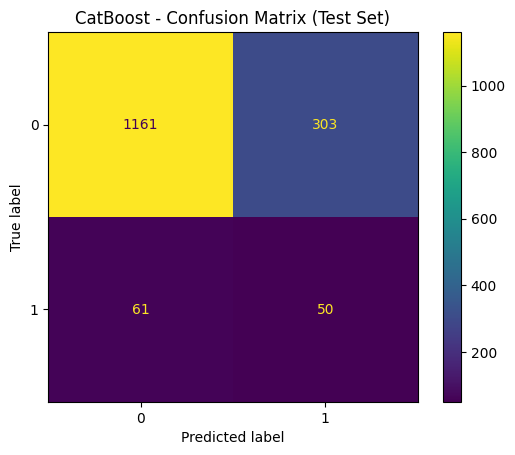

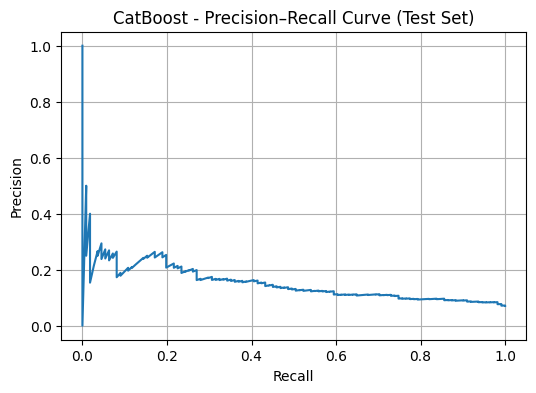


=== CatBoost (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.209338,0.021271
1,Balanced Accuracy,0.668478,0.015139
2,Macro F1,0.579426,0.008379


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

try:
    from catboost import CatBoostClassifier
except Exception as e:
    raise ImportError ("catboost is required for Model 10. Install it and run again.") from e

x = X.copy ()

# Convert to dense if we get a sparse matrix
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Class weights to deal with the imbalance
pos_count = float (np.sum (y_train == 1))
neg_count = float (np.sum (y_train == 0))
class_weights = [1.0, (neg_count / pos_count) if pos_count > 0 else 1.0]

print ()
print ("class_weights:", class_weights)

# Small grid of settings to try, chosen using validation PR AUC
learning_rate_values = [0.03, 0.1]
depth_values = [4, 6, 8]
iterations_values = [500, 1000]
l2_leaf_reg_values = [1.0, 3.0, 10.0]

scores = []

for learning_rate in learning_rate_values:
    for depth in depth_values:
        for iterations in iterations_values:
            for l2_leaf_reg in l2_leaf_reg_values:

                clf = CatBoostClassifier (
                    loss_function = "Logloss",
                    eval_metric = "AUC",
                    learning_rate = learning_rate,
                    depth = depth,
                    iterations = iterations,
                    l2_leaf_reg = l2_leaf_reg,
                    random_seed = 42,
                    verbose = False,
                    class_weights = class_weights
                )

                model = clf.fit (X_train, y_train)

                pred_train = model.predict (X_train)
                pred_val = model.predict (X_val)

                prob_train = model.predict_proba (X_train)[:, 1]
                prob_val = model.predict_proba (X_val)[:, 1]

                pr_train = average_precision_score (y_train, prob_train)
                pr_val = average_precision_score (y_val, prob_val)

                ba_train = balanced_accuracy_score (y_train, pred_train)
                ba_val = balanced_accuracy_score (y_val, pred_val)

                f1_train = f1_score (y_train, pred_train, average = "macro")
                f1_val = f1_score (y_val, pred_val, average = "macro")

                scores.append ({
                    "learning_rate": learning_rate,
                    "depth": depth,
                    "iterations": iterations,
                    "l2_leaf_reg": l2_leaf_reg,
                    "pr_train": pr_train,
                    "pr_val": pr_val,
                    "ba_train": ba_train,
                    "ba_val": ba_val,
                    "f1_train": f1_train,
                    "f1_val": f1_val
                })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (20))

best_learning_rate = float (scores_df.loc[0, "learning_rate"])
best_depth = int (scores_df.loc[0, "depth"])
best_iterations = int (scores_df.loc[0, "iterations"])
best_l2_leaf_reg = float (scores_df.loc[0, "l2_leaf_reg"])

print ()
print ("Best parameters:")
print ("learning_rate:", best_learning_rate)
print ("depth:", best_depth)
print ("iterations:", best_iterations)
print ("l2_leaf_reg:", best_l2_leaf_reg)

# Train final model on training and validation together
X_trainval = pd.concat ([X_train, X_val], axis = 0)
y_trainval = pd.concat ([y_train, y_val], axis = 0)

pos_count_tv = float (np.sum (y_trainval == 1))
neg_count_tv = float (np.sum (y_trainval == 0))
class_weights_tv = [1.0, (neg_count_tv / pos_count_tv) if pos_count_tv > 0 else 1.0]

final_clf = CatBoostClassifier (
    loss_function = "Logloss",
    eval_metric = "AUC",
    learning_rate = best_learning_rate,
    depth = best_depth,
    iterations = best_iterations,
    l2_leaf_reg = best_l2_leaf_reg,
    random_seed = 42,
    verbose = False,
    class_weights = class_weights_tv
)

final_model = final_clf.fit (X_trainval, y_trainval)

pred_test = final_model.predict (X_test)
prob_test = final_model.predict_proba (X_test)[:, 1]

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== CatBoost (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("CatBoost - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("CatBoost - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5-fold stratified CV on training and validation
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_out = cross_validate (
    final_clf,
    X_trainval,
    y_trainval,
    scoring = scoring,
    cv = skf,
    n_jobs = -1,
    return_train_score = False
)

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [
        float (np.mean (cv_out["test_pr_auc"])),
        float (np.mean (cv_out["test_balanced_accuracy"])),
        float (np.mean (cv_out["test_f1_macro"]))
    ],
    "std": [
        float (np.std (cv_out["test_pr_auc"])),
        float (np.std (cv_out["test_balanced_accuracy"])),
        float (np.std (cv_out["test_f1_macro"]))
    ]
})

print ()
print ("=== CatBoost (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["CatBoost"] = {
    "model": "CatBoost",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (cv_out["test_pr_auc"])),
    "cv_pr_auc_std": float (np.std (cv_out["test_pr_auc"])),
    "cv_balanced_accuracy_mean": float (np.mean (cv_out["test_balanced_accuracy"])),
    "cv_balanced_accuracy_std": float (np.std (cv_out["test_balanced_accuracy"])),
    "cv_f1_macro_mean": float (np.mean (cv_out["test_f1_macro"])),
    "cv_f1_macro_std": float (np.std (cv_out["test_f1_macro"])),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "learning_rate": best_learning_rate,
    "depth": best_depth,
    "iterations": best_iterations,
    "l2_leaf_reg": best_l2_leaf_reg
}


## Model 11: Deep Learning MLP

This is our first deep learning model. It is a simple feed-forward neural network that learns non-linear patterns from the input features.

Because defaults are rare, accuracy can look good even when the model misses most defaults. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune the network on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more reliable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different network sizes, dropout values, learning rates, and weight decay values.


device: cpu
x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,hidden_dims,dropout,lr,weight_decay,val_pr_auc
0,"[64, 32]",0.2,0.0010,0.0001,0.279953
1,"[128, 64]",0.2,0.0010,0.0000,0.269106
2,"[64, 32]",0.0,0.0010,0.0001,0.267178
3,"[128, 64]",0.2,0.0010,0.0001,0.261503
4,"[128, 64]",0.0,0.0010,0.0000,0.260837
5,"[128, 64]",0.0,0.0003,0.0001,0.260617
6,"[128, 64]",0.2,0.0003,0.0001,0.259449
7,"[128, 64]",0.0,0.0010,0.0001,0.255668
8,"[64, 32]",0.0,0.0010,0.0000,0.254576
9,"[128, 64]",0.0,0.0003,0.0000,0.253935



Best parameters:
hidden_dims: [64, 32]
dropout: 0.2
lr: 0.001
weight_decay: 0.0001

=== MLP (Test Set) ===
PR AUC (Average Precision) on test set: 0.13119057314337673
Balanced Accuracy on test set: 0.61326798109585
Macro F1 on test set: 0.525645522407677

Confusion Matrix (test set):
[[1123  341]
 [  60   51]]


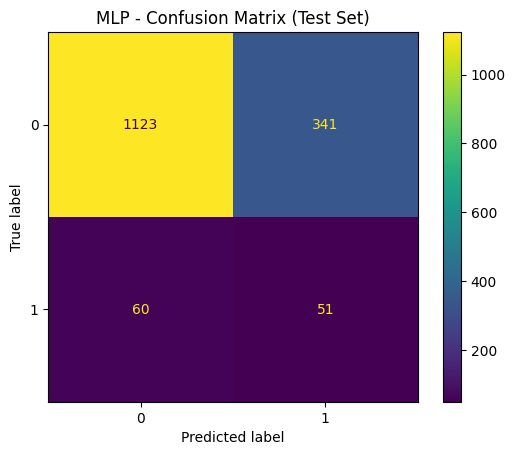

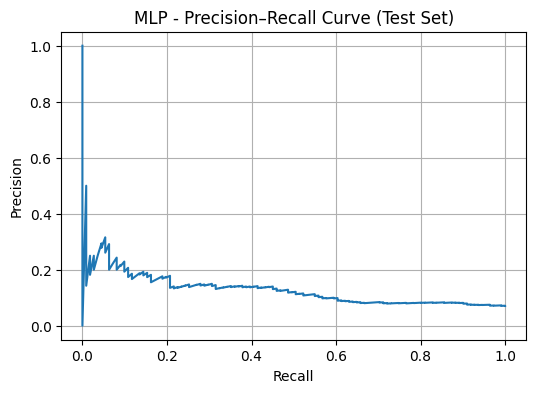


=== MLP (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.223033,0.030050
1,Balanced Accuracy,0.670831,0.019015
2,Macro F1,0.556531,0.026538


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
torch.manual_seed (42)
np.random.seed (42)

# Use GPU if available
device = torch.device ("cuda" if torch.cuda.is_available () else "cpu")
print ("device:", device)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Convert data to numpy arrays with the right dtypes for PyTorch
def to_numpy_float32 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.float32, copy = False)
    return out

def to_numpy_int64 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.int64, copy = False)
    return out

X_train_np = to_numpy_float32 (X_train)
X_val_np = to_numpy_float32 (X_val)
X_test_np = to_numpy_float32 (X_test)

y_train_np = to_numpy_int64 (y_train)
y_val_np = to_numpy_int64 (y_val)
y_test_np = to_numpy_int64 (y_test)

# Simple MLP for tabular data
class MLP (nn.Module):
    def __init__ (self, input_dim, hidden_dims, dropout):
        super ().__init__ ()

        layers = []
        prev = input_dim

        for h in hidden_dims:
            layers.append (nn.Linear (prev, h))
            layers.append (nn.ReLU ())
            layers.append (nn.Dropout (dropout))
            prev = h

        layers.append (nn.Linear (prev, 1))
        self.net = nn.Sequential (*layers)

    def forward (self, x):
        return self.net (x).squeeze (1)

# Weight positive class higher because defaults are rare
def get_pos_weight (y_arr):
    pos = float (np.sum (y_arr == 1))
    neg = float (np.sum (y_arr == 0))
    if pos == 0:
        return 1.0
    return neg / pos

# Batch prediction helper
def predict_proba (model, X_np, batch_size = 2048):
    model.eval ()
    probs = []

    with torch.no_grad ():

        n = X_np.shape[0]
        for i in range (0, n, batch_size):

            xb = torch.from_numpy (X_np[i:i + batch_size]).to (device)
            logits = model (xb)
            pb = torch.sigmoid (logits).detach ().cpu ().numpy ()
            probs.append (pb)

    return np.concatenate (probs, axis = 0)

# Train one run with early stopping based on validation PR AUC
def train_one_run (X_tr, y_tr, X_va, y_va, config):

    input_dim = X_tr.shape[1]

    model = MLP (
        input_dim = input_dim,
        hidden_dims = config["hidden_dims"],
        dropout = config["dropout"]
    ).to (device)

    pos_w = get_pos_weight (y_tr)
    pos_w_t = torch.tensor ([pos_w], dtype = torch.float32, device = device)

    loss_fn = nn.BCEWithLogitsLoss (pos_weight = pos_w_t)
    opt = torch.optim.AdamW (
        model.parameters (),
        lr = config["lr"],
        weight_decay = config["weight_decay"]
    )

    X_tr_t = torch.from_numpy (X_tr)
    y_tr_t = torch.from_numpy (y_tr.astype (np.float32))

    train_ds = torch.utils.data.TensorDataset (X_tr_t, y_tr_t)
    train_loader = torch.utils.data.DataLoader (
        train_ds,
        batch_size = config["batch_size"],
        shuffle = True,
        drop_last = False
    )

    best_state = None
    best_pr = -1.0
    patience_left = config["patience"]

    for epoch in range (1, config["max_epochs"] + 1):

        model.train ()
        losses = []

        for xb_cpu, yb_cpu in train_loader:

            xb = xb_cpu.to (device)
            yb = yb_cpu.to (device)

            opt.zero_grad ()
            logits = model (xb)
            loss = loss_fn (logits, yb)
            loss.backward ()
            opt.step ()

            losses.append (float (loss.detach ().cpu ().item ()))

        val_probs = predict_proba (model, X_va, batch_size = 4096)
        val_pr = average_precision_score (y_va, val_probs)

        if val_pr > best_pr + 1e-6:
            best_pr = val_pr
            best_state = {k: v.detach ().cpu ().clone () for k, v in model.state_dict ().items ()}
            patience_left = config["patience"]
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    if best_state is not None:
        model.load_state_dict (best_state)

    return model, best_pr

# Small tuning grid
tuning_grid = []

hidden_choices = [(128, 64), (64, 32)]
dropout_choices = [0.0, 0.2]
lr_choices = [1e-3, 3e-4]
wd_choices = [0.0, 1e-4]

for h in hidden_choices:
    for d in dropout_choices:
        for lr in lr_choices:
            for wd in wd_choices:
                tuning_grid.append ({
                    "hidden_dims": list (h),
                    "dropout": float (d),
                    "lr": float (lr),
                    "weight_decay": float (wd),
                    "batch_size": 256,
                    "max_epochs": 50,
                    "patience": 6
                })

tuning_rows = []

for cfg in tuning_grid:

    model_tmp, best_pr_val = train_one_run (
        X_train_np, y_train_np,
        X_val_np, y_val_np,
        cfg
    )

    tuning_rows.append ({
        "hidden_dims": str (cfg["hidden_dims"]),
        "dropout": cfg["dropout"],
        "lr": cfg["lr"],
        "weight_decay": cfg["weight_decay"],
        "val_pr_auc": float (best_pr_val)
    })

tuning_df = pd.DataFrame (tuning_rows).sort_values ("val_pr_auc", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (tuning_df.head (10))

best_cfg = tuning_grid[int (tuning_df.index[0])]

best_cfg = {
    "hidden_dims": eval (tuning_df.loc[0, "hidden_dims"]),
    "dropout": float (tuning_df.loc[0, "dropout"]),
    "lr": float (tuning_df.loc[0, "lr"]),
    "weight_decay": float (tuning_df.loc[0, "weight_decay"]),
    "batch_size": 256,
    "max_epochs": 60,
    "patience": 8
}

print ()
print ("Best parameters:")
print ("hidden_dims:", best_cfg["hidden_dims"])
print ("dropout:", best_cfg["dropout"])
print ("lr:", best_cfg["lr"])
print ("weight_decay:", best_cfg["weight_decay"])

# Train final model on train and validation, then test on the test set
X_trainval_np = np.concatenate ([X_train_np, X_val_np], axis = 0)
y_trainval_np = np.concatenate ([y_train_np, y_val_np], axis = 0)

final_model, _ = train_one_run (
    X_trainval_np, y_trainval_np,
    X_val_np, y_val_np,
    best_cfg
)

test_probs = predict_proba (final_model, X_test_np, batch_size = 4096)
test_pred = (test_probs >= 0.5).astype (np.int64)

pr_test = average_precision_score (y_test_np, test_probs)
ba_test = balanced_accuracy_score (y_test_np, test_pred)
f1_test = f1_score (y_test_np, test_pred, average = "macro")

print ()
print ("=== MLP (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]
cm = confusion_matrix (y_test_np, test_pred, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("MLP - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test_np, test_probs)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("MLP - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# Manual 5-fold stratified CV with the same training loop
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval_np, y_trainval_np):

    X_tr = X_trainval_np[train_index]
    y_tr = y_trainval_np[train_index]

    X_va = X_trainval_np[valid_index]
    y_va = y_trainval_np[valid_index]

    fold_cfg = dict (best_cfg)
    fold_cfg["max_epochs"] = 40
    fold_cfg["patience"] = 5

    fold_model, _ = train_one_run (X_tr, y_tr, X_va, y_va, fold_cfg)

    probs_va = predict_proba (fold_model, X_va, batch_size = 4096)
    pred_va = (probs_va >= 0.5).astype (np.int64)

    pr_scores.append (average_precision_score (y_va, probs_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [float (np.mean (pr_scores)), float (np.mean (ba_scores)), float (np.mean (f1_scores))],
    "std": [float (np.std (pr_scores)), float (np.std (ba_scores)), float (np.std (f1_scores))]
})

print ()
print ("=== MLP (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["MLP"] = {
    "model": "MLP",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "hidden_dims": str (best_cfg["hidden_dims"]),
    "dropout": float (best_cfg["dropout"]),
    "lr": float (best_cfg["lr"]),
    "weight_decay": float (best_cfg["weight_decay"])
}


## Model 12: MLP with Batch Normalisation and Dropout

This model is still a simple neural network, but it usually trains more smoothly than the basic MLP. Batch normalisation helps keep the training stable, and dropout helps reduce overfitting.

Because defaults are rare, accuracy can look good even when the model misses most defaults. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more reliable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different network sizes, dropout values, learning rates, and weight decay values.


device: cpu
x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,config_id,hidden_dims,dropout,lr,weight_decay,val_pr_auc
0,9,"[128, 64]",0.2,0.0010,0.0001,0.281494
1,10,"[128, 64]",0.2,0.0003,0.0000,0.272085
2,11,"[128, 64]",0.2,0.0003,0.0001,0.271645
3,8,"[128, 64]",0.2,0.0010,0.0000,0.262056
4,12,"[128, 64]",0.4,0.0010,0.0000,0.261994
5,14,"[128, 64]",0.4,0.0003,0.0000,0.261556
6,6,"[256, 128]",0.4,0.0003,0.0000,0.259787
7,3,"[256, 128]",0.2,0.0003,0.0001,0.258355
8,1,"[256, 128]",0.2,0.0010,0.0001,0.257230
9,5,"[256, 128]",0.4,0.0010,0.0001,0.256331



Best parameters:
hidden_dims: [128, 64]
dropout: 0.2
lr: 0.001
weight_decay: 0.0001

=== MLP + BatchNorm + Dropout (Test Set) ===
PR AUC (Average Precision) on test set: 0.13488072744549337
Balanced Accuracy on test set: 0.6355597400679367
Macro F1 on test set: 0.508811182657667

Confusion Matrix (test set):
[[1030  434]
 [  48   63]]


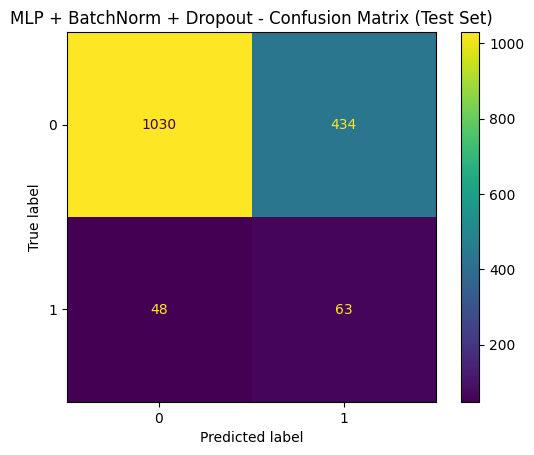

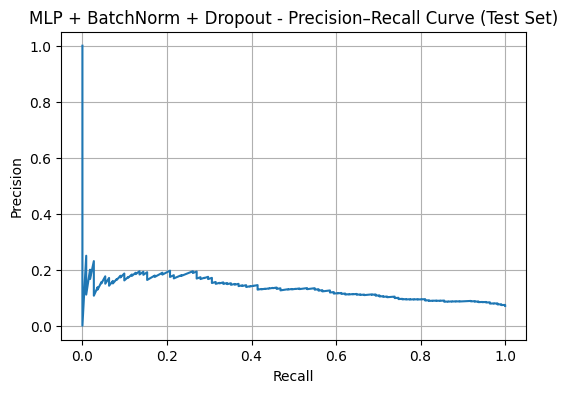


=== MLP + BatchNorm + Dropout (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.223258,0.038381
1,Balanced Accuracy,0.678035,0.010005
2,Macro F1,0.542768,0.005793


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
torch.manual_seed (42)
np.random.seed (42)

# Use GPU if available
device = torch.device ("cuda" if torch.cuda.is_available () else "cpu")
print ("device:", device)

x = X.copy ()

# Keep the scaled columns and drop the matching original ones if both exist
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Stratified split into train, validation, and test
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Convert data to numpy arrays with the right dtypes for PyTorch
def to_numpy_float32 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.float32, copy = False)
    return out

def to_numpy_int64 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.int64, copy = False)
    return out

X_train_np = to_numpy_float32 (X_train)
X_val_np = to_numpy_float32 (X_val)
X_test_np = to_numpy_float32 (X_test)

y_train_np = to_numpy_int64 (y_train)
y_val_np = to_numpy_int64 (y_val)
y_test_np = to_numpy_int64 (y_test)

# MLP with batch norm and dropout
class MLPBNDrop (nn.Module):
    def __init__ (self, input_dim, hidden_dims, dropout):
        super ().__init__ ()

        layers = []
        prev = input_dim

        for h in hidden_dims:
            layers.append (nn.Linear (prev, h))
            layers.append (nn.BatchNorm1d (h))
            layers.append (nn.ReLU ())
            layers.append (nn.Dropout (dropout))
            prev = h

        layers.append (nn.Linear (prev, 1))
        self.net = nn.Sequential (*layers)

    def forward (self, x):
        return self.net (x).squeeze (1)

# Weight positive class higher because defaults are rare
def get_pos_weight (y_arr):
    pos = float (np.sum (y_arr == 1))
    neg = float (np.sum (y_arr == 0))
    if pos == 0:
        return 1.0
    return neg / pos

# Batch prediction helper
def predict_proba (model, X_np, batch_size = 2048):
    model.eval ()
    probs = []

    with torch.no_grad ():

        n = X_np.shape[0]
        for i in range (0, n, batch_size):

            xb = torch.from_numpy (X_np[i:i + batch_size]).to (device)
            logits = model (xb)
            pb = torch.sigmoid (logits).detach ().cpu ().numpy ()
            probs.append (pb)

    return np.concatenate (probs, axis = 0)

# Train one run with early stopping based on validation PR AUC
def train_one_run (X_tr, y_tr, X_va, y_va, config):

    input_dim = X_tr.shape[1]

    model = MLPBNDrop (
        input_dim = input_dim,
        hidden_dims = config["hidden_dims"],
        dropout = config["dropout"]
    ).to (device)

    pos_w = get_pos_weight (y_tr)
    pos_w_t = torch.tensor ([pos_w], dtype = torch.float32, device = device)

    loss_fn = nn.BCEWithLogitsLoss (pos_weight = pos_w_t)

    opt = torch.optim.AdamW (
        model.parameters (),
        lr = config["lr"],
        weight_decay = config["weight_decay"]
    )

    X_tr_t = torch.from_numpy (X_tr)
    y_tr_t = torch.from_numpy (y_tr.astype (np.float32))

    train_ds = torch.utils.data.TensorDataset (X_tr_t, y_tr_t)
    train_loader = torch.utils.data.DataLoader (
        train_ds,
        batch_size = config["batch_size"],
        shuffle = True,
        drop_last = False
    )

    best_state = None
    best_pr = -1.0
    patience_left = config["patience"]

    for epoch in range (1, config["max_epochs"] + 1):

        model.train ()

        for xb_cpu, yb_cpu in train_loader:

            xb = xb_cpu.to (device)
            yb = yb_cpu.to (device)

            opt.zero_grad ()
            logits = model (xb)
            loss = loss_fn (logits, yb)
            loss.backward ()
            opt.step ()

        val_probs = predict_proba (model, X_va, batch_size = 4096)
        val_pr = average_precision_score (y_va, val_probs)

        if val_pr > best_pr + 1e-6:
            best_pr = val_pr
            best_state = {k: v.detach ().cpu ().clone () for k, v in model.state_dict ().items ()}
            patience_left = config["patience"]
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    if best_state is not None:
        model.load_state_dict (best_state)

    return model, float (best_pr)

# Small tuning grid
tuning_grid = []

hidden_choices = [(256, 128), (128, 64)]
dropout_choices = [0.2, 0.4]
lr_choices = [1e-3, 3e-4]
wd_choices = [0.0, 1e-4]

for h in hidden_choices:
    for d in dropout_choices:
        for lr in lr_choices:
            for wd in wd_choices:
                tuning_grid.append ({
                    "hidden_dims": list (h),
                    "dropout": float (d),
                    "lr": float (lr),
                    "weight_decay": float (wd),
                    "batch_size": 256,
                    "max_epochs": 40,
                    "patience": 6
                })

tuning_rows = []

for i, cfg in enumerate (tuning_grid):

    model_tmp, best_pr_val = train_one_run (
        X_train_np, y_train_np,
        X_val_np, y_val_np,
        cfg
    )

    tuning_rows.append ({
        "config_id": int (i),
        "hidden_dims": str (cfg["hidden_dims"]),
        "dropout": cfg["dropout"],
        "lr": cfg["lr"],
        "weight_decay": cfg["weight_decay"],
        "val_pr_auc": float (best_pr_val)
    })

tuning_df = pd.DataFrame (tuning_rows).sort_values ("val_pr_auc", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (tuning_df.head (10))

best_config_id = int (tuning_df.loc[0, "config_id"])
best_cfg = dict (tuning_grid[best_config_id])
best_cfg["max_epochs"] = 60
best_cfg["patience"] = 8

print ()
print ("Best parameters:")
print ("hidden_dims:", best_cfg["hidden_dims"])
print ("dropout:", best_cfg["dropout"])
print ("lr:", best_cfg["lr"])
print ("weight_decay:", best_cfg["weight_decay"])

# Build a small internal split from train and validation to use inside training
X_trainval_np = np.concatenate ([X_train_np, X_val_np], axis = 0)
y_trainval_np = np.concatenate ([y_train_np, y_val_np], axis = 0)

X_internal_train, X_internal_val, y_internal_train, y_internal_val = train_test_split (
    X_trainval_np, y_trainval_np, test_size = 0.10, stratify = y_trainval_np, random_state = 42
)

# Train final model and test on the test set
final_model, _ = train_one_run (
    X_internal_train, y_internal_train,
    X_internal_val, y_internal_val,
    best_cfg
)

test_probs = predict_proba (final_model, X_test_np, batch_size = 4096)
test_pred = (test_probs >= 0.5).astype (np.int64)

pr_test = average_precision_score (y_test_np, test_probs)
ba_test = balanced_accuracy_score (y_test_np, test_pred)
f1_test = f1_score (y_test_np, test_pred, average = "macro")

print ()
print ("=== MLP + BatchNorm + Dropout (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix on the test set
labels = [0, 1]
cm = confusion_matrix (y_test_np, test_pred, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("MLP + BatchNorm + Dropout - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve on the test set
precision, recall, _ = precision_recall_curve (y_test_np, test_probs)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("MLP + BatchNorm + Dropout - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# Manual 5-fold stratified CV with the same training loop
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval_np, y_trainval_np):

    X_tr = X_trainval_np[train_index]
    y_tr = y_trainval_np[train_index]

    X_va = X_trainval_np[valid_index]
    y_va = y_trainval_np[valid_index]

    fold_cfg = dict (best_cfg)
    fold_cfg["max_epochs"] = 35
    fold_cfg["patience"] = 5

    fold_model, _ = train_one_run (X_tr, y_tr, X_va, y_va, fold_cfg)

    probs_va = predict_proba (fold_model, X_va, batch_size = 4096)
    pred_va = (probs_va >= 0.5).astype (np.int64)

    pr_scores.append (average_precision_score (y_va, probs_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [float (np.mean (pr_scores)), float (np.mean (ba_scores)), float (np.mean (f1_scores))],
    "std": [float (np.std (pr_scores)), float (np.std (ba_scores)), float (np.std (f1_scores))]
})

print ()
print ("=== MLP + BatchNorm + Dropout (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["MLP + BatchNorm + Dropout"] = {
    "model": "MLP + BatchNorm + Dropout",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "hidden_dims": str (best_cfg["hidden_dims"]),
    "dropout": float (best_cfg["dropout"]),
    "lr": float (best_cfg["lr"]),
    "weight_decay": float (best_cfg["weight_decay"])
}


## Model 13: Residual MLP

This model is a neural network with skip connections. The skip connections help training, especially when the network is deeper, because the gradients can flow better and the model is less likely to get stuck.

Because defaults are rare, accuracy can look good even when the model misses most defaults. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more reliable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different hidden sizes, dropout values, learning rates, weight decay values, and numbers of residual blocks.


device: cpu
x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

Validation results (sorted by PR AUC):


,config_id,hidden_dim,num_blocks,dropout,lr,weight_decay,val_pr_auc
0,5,128,2,0.4,0.0010,0.0001,0.283273
1,13,128,3,0.4,0.0010,0.0001,0.277672
2,4,128,2,0.4,0.0010,0.0000,0.275402
3,23,256,2,0.4,0.0003,0.0001,0.272590
4,14,128,3,0.4,0.0003,0.0000,0.257706
5,7,128,2,0.4,0.0003,0.0001,0.256303
6,22,256,2,0.4,0.0003,0.0000,0.255274
7,10,128,3,0.2,0.0003,0.0000,0.255214
8,28,256,3,0.4,0.0010,0.0000,0.254790
9,12,128,3,0.4,0.0010,0.0000,0.251680



Best parameters:
hidden_dim: 128
num_blocks: 2
dropout: 0.4
lr: 0.001
weight_decay: 0.0001

=== Residual MLP (Test Set) ===
PR AUC (Average Precision) on test set: 0.13484343810338387
Balanced Accuracy on test set: 0.6188247673903411
Macro F1 on test set: 0.4893922160130557

Confusion Matrix (test set):
[[981 483]
 [ 48  63]]


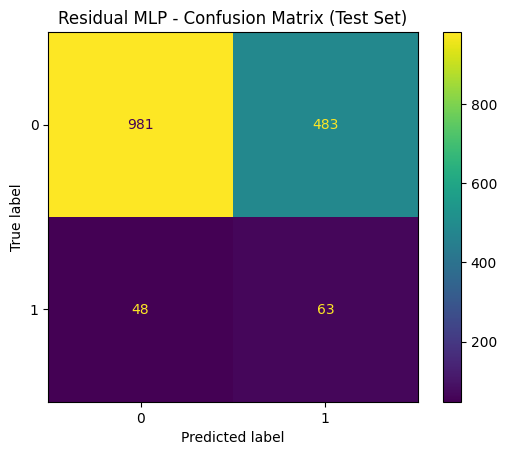

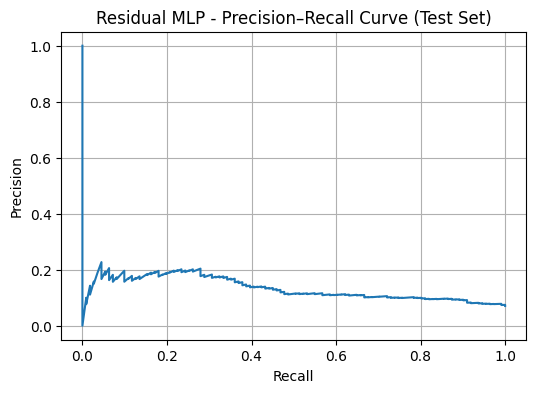


=== Residual MLP (5-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.218562,0.021930
1,Balanced Accuracy,0.671059,0.024331
2,Macro F1,0.491813,0.025328


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Set seeds so results are easier to repeat
torch.manual_seed (42)
np.random.seed (42)

# Use GPU if it is available
device = torch.device ("cuda" if torch.cuda.is_available () else "cpu")
print ("device:", device)

# Copy features
x = X.copy ()

# For neural nets we keep the scaled columns and drop the original versions
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Train, validation, test split with stratification (imbalanced target)
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Convert pandas data to numpy arrays with the right dtypes for PyTorch
def to_numpy_float32 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.float32, copy = False)
    return out

def to_numpy_int64 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.int64, copy = False)
    return out

X_train_np = to_numpy_float32 (X_train)
X_val_np = to_numpy_float32 (X_val)
X_test_np = to_numpy_float32 (X_test)

y_train_np = to_numpy_int64 (y_train)
y_val_np = to_numpy_int64 (y_val)
y_test_np = to_numpy_int64 (y_test)

# Residual block with a skip connection
class ResidualBlock (nn.Module):
    def __init__ (self, dim, dropout):
        super ().__init__ ()
        self.fc1 = nn.Linear (dim, dim)
        self.bn1 = nn.BatchNorm1d (dim)
        self.fc2 = nn.Linear (dim, dim)
        self.bn2 = nn.BatchNorm1d (dim)
        self.act = nn.ReLU ()
        self.drop = nn.Dropout (dropout)

    def forward (self, x):
        out = self.fc1 (x)
        out = self.bn1 (out)
        out = self.act (out)
        out = self.drop (out)

        out = self.fc2 (out)
        out = self.bn2 (out)

        out = out + x
        out = self.act (out)
        return out

# Residual MLP built from multiple residual blocks
class ResidualMLP (nn.Module):
    def __init__ (self, input_dim, hidden_dim, num_blocks, dropout):
        super ().__init__ ()

        self.inp = nn.Sequential (
            nn.Linear (input_dim, hidden_dim),
            nn.BatchNorm1d (hidden_dim),
            nn.ReLU (),
            nn.Dropout (dropout)
        )

        blocks = []
        for _ in range (num_blocks):
            blocks.append (ResidualBlock (hidden_dim, dropout))
        self.blocks = nn.Sequential (*blocks)

        self.out = nn.Linear (hidden_dim, 1)

    def forward (self, x):
        h = self.inp (x)
        h = self.blocks (h)
        return self.out (h).squeeze (1)

# Class imbalance handling for BCEWithLogitsLoss
def get_pos_weight (y_arr):
    pos = float (np.sum (y_arr == 1))
    neg = float (np.sum (y_arr == 0))
    if pos == 0:
        return 1.0
    return neg / pos

# Predict probabilities in batches to avoid memory issues
def predict_proba (model, X_np, batch_size = 2048):
    model.eval ()
    probs = []

    with torch.no_grad ():

        n = X_np.shape[0]
        for i in range (0, n, batch_size):

            xb = torch.from_numpy (X_np[i:i + batch_size]).to (device)
            logits = model (xb)
            pb = torch.sigmoid (logits).detach ().cpu ().numpy ()
            probs.append (pb)

    return np.concatenate (probs, axis = 0)

# Train one model run with early stopping based on PR AUC on validation
def train_one_run (X_tr, y_tr, X_va, y_va, config):

    input_dim = X_tr.shape[1]

    model = ResidualMLP (
        input_dim = input_dim,
        hidden_dim = config["hidden_dim"],
        num_blocks = config["num_blocks"],
        dropout = config["dropout"]
    ).to (device)

    pos_w = get_pos_weight (y_tr)
    pos_w_t = torch.tensor ([pos_w], dtype = torch.float32, device = device)

    loss_fn = nn.BCEWithLogitsLoss (pos_weight = pos_w_t)

    opt = torch.optim.AdamW (
        model.parameters (),
        lr = config["lr"],
        weight_decay = config["weight_decay"]
    )

    X_tr_t = torch.from_numpy (X_tr)
    y_tr_t = torch.from_numpy (y_tr.astype (np.float32))

    train_ds = torch.utils.data.TensorDataset (X_tr_t, y_tr_t)
    train_loader = torch.utils.data.DataLoader (
        train_ds,
        batch_size = config["batch_size"],
        shuffle = True,
        drop_last = False
    )

    best_state = None
    best_pr = -1.0
    patience_left = config["patience"]

    for epoch in range (1, config["max_epochs"] + 1):

        model.train ()

        for xb_cpu, yb_cpu in train_loader:

            xb = xb_cpu.to (device)
            yb = yb_cpu.to (device)

            opt.zero_grad ()
            logits = model (xb)
            loss = loss_fn (logits, yb)
            loss.backward ()
            opt.step ()

        val_probs = predict_proba (model, X_va, batch_size = 4096)
        val_pr = average_precision_score (y_va, val_probs)

        if val_pr > best_pr + 1e-6:
            best_pr = val_pr
            best_state = {k: v.detach ().cpu ().clone () for k, v in model.state_dict ().items ()}
            patience_left = config["patience"]
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    if best_state is not None:
        model.load_state_dict (best_state)

    return model, float (best_pr)

# Small tuning grid for the main settings
tuning_grid = []

hidden_dim_values = [128, 256]
num_blocks_values = [2, 3]
dropout_values = [0.2, 0.4]
lr_values = [1e-3, 3e-4]
wd_values = [0.0, 1e-4]

for hidden_dim in hidden_dim_values:
    for num_blocks in num_blocks_values:
        for dropout in dropout_values:
            for lr in lr_values:
                for wd in wd_values:

                    tuning_grid.append ({
                        "hidden_dim": int (hidden_dim),
                        "num_blocks": int (num_blocks),
                        "dropout": float (dropout),
                        "lr": float (lr),
                        "weight_decay": float (wd),
                        "batch_size": 256,
                        "max_epochs": 35,
                        "patience": 6
                    })

# Train each config and keep the best PR AUC on validation
tuning_rows = []

for i, cfg in enumerate (tuning_grid):

    model_tmp, best_pr_val = train_one_run (
        X_train_np, y_train_np,
        X_val_np, y_val_np,
        cfg
    )

    tuning_rows.append ({
        "config_id": int (i),
        "hidden_dim": int (cfg["hidden_dim"]),
        "num_blocks": int (cfg["num_blocks"]),
        "dropout": float (cfg["dropout"]),
        "lr": float (cfg["lr"]),
        "weight_decay": float (cfg["weight_decay"]),
        "val_pr_auc": float (best_pr_val)
    })

tuning_df = pd.DataFrame (tuning_rows).sort_values ("val_pr_auc", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (tuning_df.head (10))

best_config_id = int (tuning_df.loc[0, "config_id"])
best_cfg = dict (tuning_grid[best_config_id])
best_cfg["max_epochs"] = 55
best_cfg["patience"] = 8

print ()
print ("Best parameters:")
print ("hidden_dim:", best_cfg["hidden_dim"])
print ("num_blocks:", best_cfg["num_blocks"])
print ("dropout:", best_cfg["dropout"])
print ("lr:", best_cfg["lr"])
print ("weight_decay:", best_cfg["weight_decay"])

# Combine train and validation, then do a small internal split for training
X_trainval_np = np.concatenate ([X_train_np, X_val_np], axis = 0)
y_trainval_np = np.concatenate ([y_train_np, y_val_np], axis = 0)

X_internal_train, X_internal_val, y_internal_train, y_internal_val = train_test_split (
    X_trainval_np, y_trainval_np, test_size = 0.10, stratify = y_trainval_np, random_state = 42
)

final_model, _ = train_one_run (
    X_internal_train, y_internal_train,
    X_internal_val, y_internal_val,
    best_cfg
)

# Test set evaluation
test_probs = predict_proba (final_model, X_test_np, batch_size = 4096)
test_pred = (test_probs >= 0.5).astype (np.int64)

pr_test = average_precision_score (y_test_np, test_probs)
ba_test = balanced_accuracy_score (y_test_np, test_pred)
f1_test = f1_score (y_test_np, test_pred, average = "macro")

print ()
print ("=== Residual MLP (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix
labels = [0, 1]
cm = confusion_matrix (y_test_np, test_pred, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("Residual MLP - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve
precision, recall, _ = precision_recall_curve (y_test_np, test_probs)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("Residual MLP - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 5 fold stratified CV on train and validation
skf = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval_np, y_trainval_np):

    X_tr = X_trainval_np[train_index]
    y_tr = y_trainval_np[train_index]

    X_va = X_trainval_np[valid_index]
    y_va = y_trainval_np[valid_index]

    fold_cfg = dict (best_cfg)
    fold_cfg["max_epochs"] = 30
    fold_cfg["patience"] = 5

    fold_model, _ = train_one_run (X_tr, y_tr, X_va, y_va, fold_cfg)

    probs_va = predict_proba (fold_model, X_va, batch_size = 4096)
    pred_va = (probs_va >= 0.5).astype (np.int64)

    pr_scores.append (average_precision_score (y_va, probs_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [float (np.mean (pr_scores)), float (np.mean (ba_scores)), float (np.mean (f1_scores))],
    "std": [float (np.std (pr_scores)), float (np.std (ba_scores)), float (np.std (f1_scores))]
})

print ()
print ("=== Residual MLP (5-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["Residual MLP"] = {
    "model": "Residual MLP",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "hidden_dim": int (best_cfg["hidden_dim"]),
    "num_blocks": int (best_cfg["num_blocks"]),
    "dropout": float (best_cfg["dropout"]),
    "lr": float (best_cfg["lr"]),
    "weight_decay": float (best_cfg["weight_decay"])
}


## Model 14: TabNet

TabNet is a deep learning model designed for tabular data. It learns which features to focus on at each step, so it can behave a bit like a smart tree model, but it is still a neural network.

Because defaults are rare, accuracy can look good even when the model misses most defaults. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more reliable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different sizes for the decision and attention blocks, different numbers of decision steps, different learning rates, and different dropout values.


## WARNING!!!

If you want to run the next TabNet model, install the package once:

`!pip install -q pytorch-tabnet` (around 50 kB)

If you do not want to install extra packages, you can simply skip the TabNet model section.

In [34]:
!pip install -q pytorch-tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 781.8 kB/s eta 0:00:00


x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

class_weights: {0: 1.0, 1: 13.137724550898204}

Early stopping occurred at epoch 11 with best_epoch = 6 and best_val_auc = 0.70005


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Validation results (sorted by PR AUC):


,n_d,n_a,n_steps,gamma,lr,lambda_sparse,pr_train,pr_val,ba_train,ba_val,f1_train,f1_val
0,16,16,3,1.3,0.02,0.0001,0.133693,0.152027,0.502585,0.509412,0.492564,0.503955



Best parameters:
n_d: 16
n_a: 16
n_steps: 3
gamma: 1.3
lr: 0.02
lambda_sparse: 0.0001

Early stopping occurred at epoch 17 with best_epoch = 9 and best_val_auc = 0.74466


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



=== TabNet (Test Set) ===
PR AUC (Average Precision) on test set: 0.1449476780564402
Balanced Accuracy on test set: 0.5021137941219909
Macro F1 on test set: 0.48910280047353816

Confusion Matrix (test set):
[[1457    7]
 [ 110    1]]


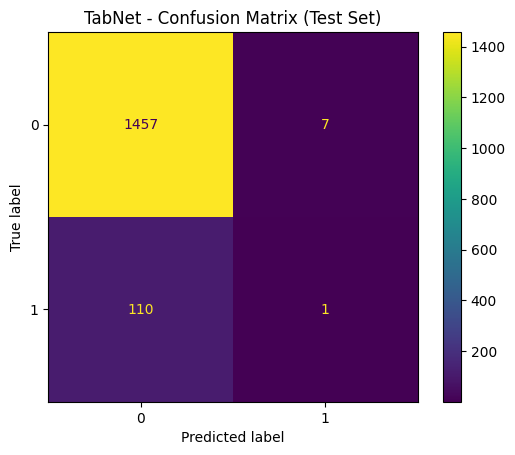

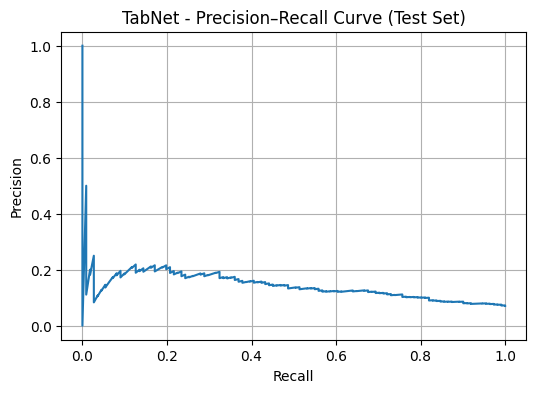


Early stopping occurred at epoch 13 with best_epoch = 8 and best_val_auc = 0.59594


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 30 with best_epoch = 25 and best_val_auc = 0.72169


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 17 with best_epoch = 12 and best_val_auc = 0.67989


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



=== TabNet (3-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.135065,0.033169
1,Balanced Accuracy,0.524019,0.020569
2,Macro F1,0.525392,0.027718


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TabNet model import
try:
    from pytorch_tabnet.tab_model import TabNetClassifier
except Exception as e:
    raise ImportError ("pytorch-tabnet is required for Model 14. Install it and run again.") from e

# Seed for repeatable runs
np.random.seed (42)

# Copy features
x = X.copy ()

# For TabNet we keep the scaled columns and drop the original versions
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

# Convert sparse to dense if needed
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

# Move to numpy for TabNet
if hasattr (x, "to_numpy"):
    x = x.to_numpy ()

if hasattr (y, "to_numpy"):
    y_np = y.to_numpy ()
else:
    y_np = np.asarray (y)

# Set dtypes expected by the model
x = x.astype (np.float32, copy = False)
y_np = y_np.astype (np.int64, copy = False)

print ("x shape:", x.shape)
print ("y shape:", y_np.shape)

# Train, validation, test split with stratification
X_train, X_test, y_train, y_test = train_test_split (
    x, y_np, test_size = 0.20, stratify = y_np, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Class weights for imbalanced target
def get_class_weights (y_arr):
    pos = float (np.sum (y_arr == 1))
    neg = float (np.sum (y_arr == 0))
    if pos == 0:
        return {0: 1.0, 1: 1.0}
    w1 = neg / pos
    return {0: 1.0, 1: float (w1)}

class_weights = get_class_weights (y_train)

print ()
print ("class_weights:", class_weights)

# Small tuning grid (kept small to avoid long runtimes)
nd_values = [16]
na_values = [16]
n_steps_values = [3]
gamma_values = [1.3]
lr_values = [0.02]
lambda_sparse_values = [1e-4]

scores = []

# Tune using validation PR AUC
for nd in nd_values:
    for na in na_values:
        for n_steps in n_steps_values:
            for gamma in gamma_values:
                for lr in lr_values:
                    for lambda_sparse in lambda_sparse_values:

                        clf = TabNetClassifier (
                            n_d = nd,
                            n_a = na,
                            n_steps = n_steps,
                            gamma = gamma,
                            lambda_sparse = lambda_sparse,
                            optimizer_fn = torch.optim.Adam,
                            optimizer_params = {"lr": lr},
                            mask_type = "sparsemax",
                            seed = 42,
                            verbose = 0
                        )

                        clf.fit (
                            X_train = X_train,
                            y_train = y_train,
                            eval_set = [(X_val, y_val)],
                            eval_name = ["val"],
                            eval_metric = ["auc"],
                            max_epochs = 40,
                            patience = 5,
                            batch_size = 2048,
                            virtual_batch_size = 256,
                            num_workers = 0,
                            weights = class_weights,
                            drop_last = False
                        )

                        prob_train = clf.predict_proba (X_train)[:, 1]
                        prob_val = clf.predict_proba (X_val)[:, 1]

                        pred_train = (prob_train >= 0.5).astype (np.int64)
                        pred_val = (prob_val >= 0.5).astype (np.int64)

                        pr_train = average_precision_score (y_train, prob_train)
                        pr_val = average_precision_score (y_val, prob_val)

                        ba_train = balanced_accuracy_score (y_train, pred_train)
                        ba_val = balanced_accuracy_score (y_val, pred_val)

                        f1_train = f1_score (y_train, pred_train, average = "macro")
                        f1_val = f1_score (y_val, pred_val, average = "macro")

                        scores.append ({
                            "n_d": nd,
                            "n_a": na,
                            "n_steps": n_steps,
                            "gamma": gamma,
                            "lr": lr,
                            "lambda_sparse": lambda_sparse,
                            "pr_train": pr_train,
                            "pr_val": pr_val,
                            "ba_train": ba_train,
                            "ba_val": ba_val,
                            "f1_train": f1_train,
                            "f1_val": f1_val
                        })

scores_df = pd.DataFrame (scores).sort_values ("pr_val", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (scores_df.head (10))

best_n_d = int (scores_df.loc[0, "n_d"])
best_n_a = int (scores_df.loc[0, "n_a"])
best_n_steps = int (scores_df.loc[0, "n_steps"])
best_gamma = float (scores_df.loc[0, "gamma"])
best_lr = float (scores_df.loc[0, "lr"])
best_lambda_sparse = float (scores_df.loc[0, "lambda_sparse"])

print ()
print ("Best parameters:")
print ("n_d:", best_n_d)
print ("n_a:", best_n_a)
print ("n_steps:", best_n_steps)
print ("gamma:", best_gamma)
print ("lr:", best_lr)
print ("lambda_sparse:", best_lambda_sparse)

# Train final model on train and validation combined
X_trainval = np.vstack ([X_train, X_val])
y_trainval = np.concatenate ([y_train, y_val])

class_weights_tv = get_class_weights (y_trainval)

final_clf = TabNetClassifier (
    n_d = best_n_d,
    n_a = best_n_a,
    n_steps = best_n_steps,
    gamma = best_gamma,
    lambda_sparse = best_lambda_sparse,
    optimizer_fn = torch.optim.Adam,
    optimizer_params = {"lr": best_lr},
    mask_type = "sparsemax",
    seed = 42,
    verbose = 0
)

final_clf.fit (
    X_train = X_trainval,
    y_train = y_trainval,
    eval_set = [(X_val, y_val)],
    eval_name = ["val"],
    eval_metric = ["auc"],
    max_epochs = 60,
    patience = 8,
    batch_size = 2048,
    virtual_batch_size = 256,
    num_workers = 0,
    weights = class_weights_tv,
    drop_last = False
)

# Test set evaluation
prob_test = final_clf.predict_proba (X_test)[:, 1]
pred_test = (prob_test >= 0.5).astype (np.int64)

pr_test = average_precision_score (y_test, prob_test)
ba_test = balanced_accuracy_score (y_test, pred_test)
f1_test = f1_score (y_test, pred_test, average = "macro")

print ()
print ("=== TabNet (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

# Confusion matrix
labels = [0, 1]

cm = confusion_matrix (y_test, pred_test, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("TabNet - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision recall curve
precision, recall, _ = precision_recall_curve (y_test, prob_test)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("TabNet - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# Small helper for CV indexing
def take_rows (a, idx):
    return a[idx]

# 3 fold CV to keep runtime reasonable
skf = StratifiedKFold (n_splits = 3, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval, y_trainval):

    X_tr = take_rows (X_trainval, train_index)
    y_tr = take_rows (y_trainval, train_index)

    X_va = take_rows (X_trainval, valid_index)
    y_va = take_rows (y_trainval, valid_index)

    cw = get_class_weights (y_tr)

    fold_clf = TabNetClassifier (
        n_d = best_n_d,
        n_a = best_n_a,
        n_steps = best_n_steps,
        gamma = best_gamma,
        lambda_sparse = best_lambda_sparse,
        optimizer_fn = torch.optim.Adam,
        optimizer_params = {"lr": best_lr},
        mask_type = "sparsemax",
        seed = 42,
        verbose = 0
    )

    fold_clf.fit (
        X_train = X_tr,
        y_train = y_tr,
        eval_set = [(X_va, y_va)],
        eval_name = ["val"],
        eval_metric = ["auc"],
        max_epochs = 35,
        patience = 5,
        batch_size = 2048,
        virtual_batch_size = 256,
        num_workers = 0,
        weights = cw,
        drop_last = False
    )

    prob_va = fold_clf.predict_proba (X_va)[:, 1]
    pred_va = (prob_va >= 0.5).astype (np.int64)

    pr_scores.append (average_precision_score (y_va, prob_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [float (np.mean (pr_scores)), float (np.mean (ba_scores)), float (np.mean (f1_scores))],
    "std": [float (np.std (pr_scores)), float (np.std (ba_scores)), float (np.std (f1_scores))]
})

print ()
print ("=== TabNet (3-Fold CV on Train+Validation) ===")
display (cv_summary)

# Store results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["TabNet"] = {
    "model": "TabNet",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "n_d": int (best_n_d),
    "n_a": int (best_n_a),
    "n_steps": int (best_n_steps),
    "gamma": float (best_gamma),
    "lr": float (best_lr),
    "lambda_sparse": float (best_lambda_sparse),
    "batch_size": 2048,
    "virtual_batch_size": 256,
    "cv_folds": 3
}


## Model 15: FT-Transformer (tabular transformer)

FT-Transformer is a transformer model adapted for tabular data. Instead of trees, it turns each feature into a small token vector, then uses self-attention to learn how features interact. This can work well when the target depends on combinations of features. The main idea is similar to GPT style transformers, but here the tokens represent table features instead of words.

Because defaults are rare, accuracy can look good even when the model misses most defaults. We mainly use PR AUC (Average Precision). We also report Balanced Accuracy and Macro F1 so we can compare models fairly.

We split the data into train, validation, and test with stratification. We tune on the validation set using PR AUC, then we run 5-fold stratified cross-validation on train+validation for a more reliable score. Finally, we show a confusion matrix and a precision–recall curve on the test set.

Hyperparameters tuned: we try different transformer width, number of layers, number of attention heads, dropout, learning rate, and weight decay.

For best performance, switch Colab to GPU Runtime or TPU Runtime:
Runtime → Change runtime type → Hardware accelerator → GPU (or TPU)


device: cpu
x shape: (7871, 79)
y shape: (7871,)

X_train: (4722, 79)
X_val  : (1574, 79)
X_test : (1575, 79)

n_features: 79


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(



Validation results (sorted by PR AUC):


,config_id,d_token,n_layers,n_heads,dropout,lr,weight_decay,val_pr_auc
0,0,32,2,4,0.1,0.001,0.0001,0.229902



Best parameters:
d_token: 32
n_layers: 2
n_heads: 4
dropout: 0.1
lr: 0.001
weight_decay: 0.0001


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(



=== FT-Transformer (Test Set) ===
PR AUC (Average Precision) on test set: 0.16109927713791292
Balanced Accuracy on test set: 0.6193509082853346
Macro F1 on test set: 0.3965415981474645

Confusion Matrix (test set):
[[666 798]
 [ 24  87]]


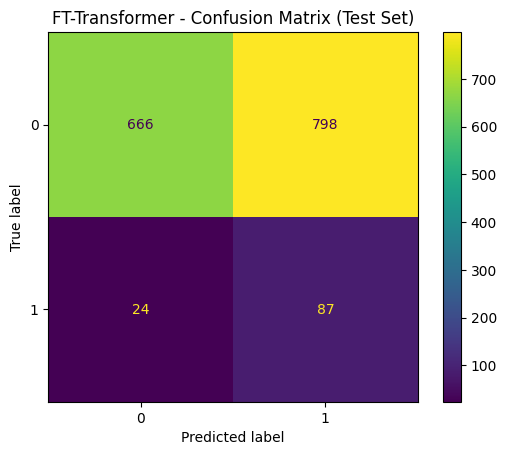

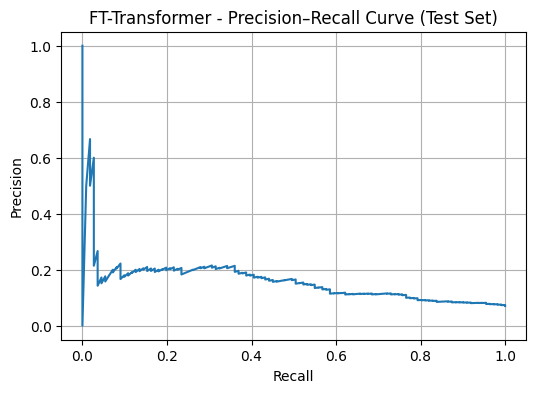

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(



=== FT-Transformer (3-Fold CV on Train+Validation) ===


,metric,mean,std
0,PR AUC (Average Precision),0.194310,0.008409
1,Balanced Accuracy,0.621532,0.049784
2,Macro F1,0.452639,0.173782


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
torch.manual_seed (42)
np.random.seed (42)

# Use GPU if available
device = torch.device ("cuda" if torch.cuda.is_available () else "cpu")
print ("device:", device)

# Copy features
x = X.copy ()

# Keep only the scaled columns for models that need scaling
mm_cols = [c for c in x.columns if c.endswith ("_mm")]
orig_cols = [c[:-3] for c in mm_cols if c[:-3] in x.columns]
x = x.drop (columns = orig_cols, errors = "ignore")

# If data is sparse, convert to dense array
try:
    import scipy.sparse as sp
    if sp.issparse (x):
        x = x.toarray ()
except Exception:
    pass

print ("x shape:", x.shape)
print ("y shape:", y.shape)

# Train, validation, test split with stratification
X_train, X_test, y_train, y_test = train_test_split (
    x, y, test_size = 0.20, stratify = y, random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split (
    X_train, y_train, test_size = 0.25, stratify = y_train, random_state = 42
)

print ()
print ("X_train:", X_train.shape)
print ("X_val  :", X_val.shape)
print ("X_test :", X_test.shape)

# Helper conversions for PyTorch
def to_numpy_float32 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.float32, copy = False)
    return out

def to_numpy_int64 (a):
    if hasattr (a, "to_numpy"):
        out = a.to_numpy ()
    else:
        out = np.asarray (a)
    out = out.astype (np.int64, copy = False)
    return out

X_train_np = to_numpy_float32 (X_train)
X_val_np = to_numpy_float32 (X_val)
X_test_np = to_numpy_float32 (X_test)

y_train_np = to_numpy_int64 (y_train)
y_val_np = to_numpy_int64 (y_val)
y_test_np = to_numpy_int64 (y_test)

n_features = int (X_train_np.shape[1])
print ()
print ("n_features:", n_features)

# Weight for BCE loss to handle imbalance
def get_pos_weight (y_arr):
    pos = float (np.sum (y_arr == 1))
    neg = float (np.sum (y_arr == 0))
    if pos == 0:
        return 1.0
    return neg / pos

# Simple FT-Transformer style model for tabular data
class FTTransformer (nn.Module):
    def __init__ (self, n_features, d_token, n_layers, n_heads, dropout, d_ff_mult = 4):
        super ().__init__ ()

        self.n_features = n_features
        self.d_token = d_token

        # Per-feature embeddings (feature -> token)
        self.weight = nn.Parameter (torch.empty (n_features, d_token))
        self.bias = nn.Parameter (torch.empty (n_features, d_token))
        nn.init.xavier_uniform_ (self.weight)
        nn.init.zeros_ (self.bias)

        # CLS token to pool the sequence
        self.cls = nn.Parameter (torch.zeros (1, 1, d_token))

        d_ff = int (d_token * d_ff_mult)

        enc_layer = nn.TransformerEncoderLayer (
            d_model = d_token,
            nhead = n_heads,
            dim_feedforward = d_ff,
            dropout = dropout,
            activation = "gelu",
            batch_first = True,
            norm_first = True
        )

        self.encoder = nn.TransformerEncoder (enc_layer, num_layers = n_layers)

        # Final head for binary classification
        self.head = nn.Sequential (
            nn.LayerNorm (d_token),
            nn.Linear (d_token, 1)
        )

    def forward (self, x):
        tokens = x.unsqueeze (-1) * self.weight.unsqueeze (0) + self.bias.unsqueeze (0)
        cls = self.cls.expand (x.shape[0], -1, -1)
        z = torch.cat ([cls, tokens], dim = 1)
        z = self.encoder (z)
        cls_out = z[:, 0, :]
        logits = self.head (cls_out).squeeze (1)
        return logits

# Predict probabilities in batches
def predict_proba (model, X_np, batch_size = 8192):
    model.eval ()
    probs = []

    with torch.no_grad ():

        n = X_np.shape[0]
        for i in range (0, n, batch_size):

            xb = torch.from_numpy (X_np[i:i + batch_size]).to (device)
            logits = model (xb)
            pb = torch.sigmoid (logits).detach ().cpu ().numpy ()
            probs.append (pb)

    return np.concatenate (probs, axis = 0)

# Train one run with early stopping on validation PR AUC
def train_one_run (X_tr, y_tr, X_va, y_va, config):

    model = FTTransformer (
        n_features = X_tr.shape[1],
        d_token = config["d_token"],
        n_layers = config["n_layers"],
        n_heads = config["n_heads"],
        dropout = config["dropout"]
    ).to (device)

    pos_w = get_pos_weight (y_tr)
    pos_w_t = torch.tensor ([pos_w], dtype = torch.float32, device = device)

    loss_fn = nn.BCEWithLogitsLoss (pos_weight = pos_w_t)

    opt = torch.optim.AdamW (
        model.parameters (),
        lr = config["lr"],
        weight_decay = config["weight_decay"]
    )

    X_tr_t = torch.from_numpy (X_tr)
    y_tr_t = torch.from_numpy (y_tr.astype (np.float32))

    train_ds = torch.utils.data.TensorDataset (X_tr_t, y_tr_t)
    train_loader = torch.utils.data.DataLoader (
        train_ds,
        batch_size = config["batch_size"],
        shuffle = True,
        drop_last = False
    )

    best_state = None
    best_pr = -1.0
    patience_left = config["patience"]

    for epoch in range (1, config["max_epochs"] + 1):

        model.train ()

        for xb_cpu, yb_cpu in train_loader:

            xb = xb_cpu.to (device)
            yb = yb_cpu.to (device)

            opt.zero_grad ()
            logits = model (xb)
            loss = loss_fn (logits, yb)
            loss.backward ()
            opt.step ()

        val_probs = predict_proba (model, X_va, batch_size = 8192)
        val_pr = average_precision_score (y_va, val_probs)

        if val_pr > best_pr + 1e-6:
            best_pr = val_pr
            best_state = {k: v.detach ().cpu ().clone () for k, v in model.state_dict ().items ()}
            patience_left = config["patience"]
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    if best_state is not None:
        model.load_state_dict (best_state)

    return model, float (best_pr)

# Small tuning grid (kept minimal because training is heavier)
tuning_grid = [
    {"d_token": 32, "n_layers": 2, "n_heads": 4, "dropout": 0.10, "lr": 1e-3, "weight_decay": 1e-4}
]

for cfg in tuning_grid:
    cfg["batch_size"] = 512
    cfg["max_epochs"] = 20
    cfg["patience"] = 3

tuning_rows = []

for i, cfg in enumerate (tuning_grid):

    model_tmp, best_pr_val = train_one_run (
        X_train_np, y_train_np,
        X_val_np, y_val_np,
        cfg
    )

    tuning_rows.append ({
        "config_id": int (i),
        "d_token": int (cfg["d_token"]),
        "n_layers": int (cfg["n_layers"]),
        "n_heads": int (cfg["n_heads"]),
        "dropout": float (cfg["dropout"]),
        "lr": float (cfg["lr"]),
        "weight_decay": float (cfg["weight_decay"]),
        "val_pr_auc": float (best_pr_val)
    })

tuning_df = pd.DataFrame (tuning_rows).sort_values ("val_pr_auc", ascending = False).reset_index (drop = True)

print ()
print ("Validation results (sorted by PR AUC):")
display (tuning_df)

best_config_id = int (tuning_df.loc[0, "config_id"])
best_cfg = dict (tuning_grid[best_config_id])
best_cfg["batch_size"] = 512
best_cfg["max_epochs"] = 30
best_cfg["patience"] = 5

print ()
print ("Best parameters:")
print ("d_token:", best_cfg["d_token"])
print ("n_layers:", best_cfg["n_layers"])
print ("n_heads:", best_cfg["n_heads"])
print ("dropout:", best_cfg["dropout"])
print ("lr:", best_cfg["lr"])
print ("weight_decay:", best_cfg["weight_decay"])

# Train final model using train+val, keep a small internal split for early stopping
X_trainval_np = np.concatenate ([X_train_np, X_val_np], axis = 0)
y_trainval_np = np.concatenate ([y_train_np, y_val_np], axis = 0)

X_internal_train, X_internal_val, y_internal_train, y_internal_val = train_test_split (
    X_trainval_np, y_trainval_np, test_size = 0.10, stratify = y_trainval_np, random_state = 42
)

final_model, _ = train_one_run (
    X_internal_train, y_internal_train,
    X_internal_val, y_internal_val,
    best_cfg
)

# Test set evaluation
test_probs = predict_proba (final_model, X_test_np, batch_size = 8192)
test_pred = (test_probs >= 0.5).astype (np.int64)

pr_test = average_precision_score (y_test_np, test_probs)
ba_test = balanced_accuracy_score (y_test_np, test_pred)
f1_test = f1_score (y_test_np, test_pred, average = "macro")

print ()
print ("=== FT-Transformer (Test Set) ===")
print ("PR AUC (Average Precision) on test set:", pr_test)
print ("Balanced Accuracy on test set:", ba_test)
print ("Macro F1 on test set:", f1_test)

labels = [0, 1]
cm = confusion_matrix (y_test_np, test_pred, labels = labels)

print ()
print ("Confusion Matrix (test set):")
print (cm)

disp = ConfusionMatrixDisplay (confusion_matrix = cm, display_labels = labels)
disp.plot ()
plt.title ("FT-Transformer - Confusion Matrix (Test Set)")
plt.grid (False)
plt.show ()

# Precision-recall curve on test set
precision, recall, _ = precision_recall_curve (y_test_np, test_probs)

plt.figure (figsize = (6, 4))
plt.plot (recall, precision)
plt.title ("FT-Transformer - Precision–Recall Curve (Test Set)")
plt.xlabel ("Recall")
plt.ylabel ("Precision")
plt.grid (True)
plt.show ()

# 3-fold CV on train+val for a quick stability check
skf = StratifiedKFold (n_splits = 3, shuffle = True, random_state = 42)

pr_scores = []
ba_scores = []
f1_scores = []

for train_index, valid_index in skf.split (X_trainval_np, y_trainval_np):

    X_tr = X_trainval_np[train_index]
    y_tr = y_trainval_np[train_index]

    X_va = X_trainval_np[valid_index]
    y_va = y_trainval_np[valid_index]

    fold_cfg = dict (best_cfg)
    fold_cfg["max_epochs"] = 15
    fold_cfg["patience"] = 2

    fold_model, _ = train_one_run (X_tr, y_tr, X_va, y_va, fold_cfg)

    probs_va = predict_proba (fold_model, X_va, batch_size = 8192)
    pred_va = (probs_va >= 0.5).astype (np.int64)

    pr_scores.append (average_precision_score (y_va, probs_va))
    ba_scores.append (balanced_accuracy_score (y_va, pred_va))
    f1_scores.append (f1_score (y_va, pred_va, average = "macro"))

cv_summary = pd.DataFrame ({
    "metric": ["PR AUC (Average Precision)", "Balanced Accuracy", "Macro F1"],
    "mean": [float (np.mean (pr_scores)), float (np.mean (ba_scores)), float (np.mean (f1_scores))],
    "std": [float (np.std (pr_scores)), float (np.std (ba_scores)), float (np.std (f1_scores))]
})

print ()
print ("=== FT-Transformer (3-Fold CV on Train+Validation) ===")
display (cv_summary)

# Save results for the final comparison table
if "model_results" not in globals ():
    model_results = {}

elif isinstance (model_results, list):

    new_model_results = {}

    for item in model_results:
        if isinstance (item, dict) and "model" in item:
            new_model_results[item["model"]] = item

    model_results = new_model_results

elif not isinstance (model_results, dict):
    model_results = {}

model_results["FT-Transformer"] = {
    "model": "FT-Transformer",
    "primary_metric": "PR AUC (Average Precision)",
    "cv_pr_auc_mean": float (np.mean (pr_scores)),
    "cv_pr_auc_std": float (np.std (pr_scores)),
    "cv_balanced_accuracy_mean": float (np.mean (ba_scores)),
    "cv_balanced_accuracy_std": float (np.std (ba_scores)),
    "cv_f1_macro_mean": float (np.mean (f1_scores)),
    "cv_f1_macro_std": float (np.std (f1_scores)),
    "test_pr_auc": float (pr_test),
    "test_balanced_accuracy": float (ba_test),
    "test_f1_macro": float (f1_test),
    "d_token": int (best_cfg["d_token"]),
    "n_layers": int (best_cfg["n_layers"]),
    "n_heads": int (best_cfg["n_heads"]),
    "dropout": float (best_cfg["dropout"]),
    "lr": float (best_cfg["lr"]),
    "weight_decay": float (best_cfg["weight_decay"]),
    "batch_size": int (best_cfg["batch_size"]),
    "cv_folds": 3
}


## Compare all 15 models

We have been saving each model’s results in `model_results`. In this part we will:

- build one clean leaderboard table for all models
- rank models mainly by CV PR AUC (Average Precision)
- also compare CV Balanced Accuracy and CV Macro F1
- plot the results (CV mean with standard deviation, plus a few scatter plots to show trade-offs)
- discuss what we see in the numbers (performance vs stability, PR AUC vs Balanced Accuracy, CV vs test gaps)
- list limitations and issues from our data and workflow
- suggest next steps (evaluation, threshold choice, calibration, modelling, and data improvements)


In [37]:
import numpy as np
import pandas as pd

from IPython.display import display

# Make sure model_results is always a dictionary, even if it was saved in a different format
def ensure_model_results_dict (model_results):
    if model_results is None:
        return {}
    if isinstance (model_results, dict):
        return model_results
    if isinstance (model_results, list):
        out = {}
        for item in model_results:
            if isinstance (item, dict) and "model" in item:
                out[item["model"]] = item
        return out
    return {}

# Load model_results from the notebook state
model_results = ensure_model_results_dict (globals ().get ("model_results", None))

# Quick check to see how many models we have saved
print ("models in model_results:", len (model_results))
if len (model_results) > 0:
    print ("model names:", list (model_results.keys ()))

# If not all models were run, the comparison will still work but it will not include everything
if len (model_results) < 15:
    print ()
    print ("Warning: We have fewer than 15 models saved in model_results.")
    print ("We can still compare what we have, but the leaderboard will be incomplete.")


models in model_results: 15
model names: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'k-Nearest Neighbours', 'Naive Bayes', 'Linear SVM', 'Histogram Gradient Boosting', 'XGBoost', 'LightGBM', 'CatBoost', 'MLP', 'MLP + BatchNorm + Dropout', 'Residual MLP', 'TabNet', 'FT-Transformer']


## Step 1 — Build one leaderboard table for all models

Here we build one results table (leaderboard) from `model_results`. The aim is to make every model easy to compare in the same place.

For each model we keep:
- CV mean and CV std for PR AUC, Balanced Accuracy, and Macro F1
- Test PR AUC, Test Balanced Accuracy, and Test Macro F1

We also add a few extra columns that help with ranking and interpretation:
- rank_cv_pr_auc: ranking by CV PR AUC mean (1 is best)
- stability_cv_pr_auc_std: the CV PR AUC standard deviation, where lower means more stable
- cv_to_test_pr_auc_drop: the difference between CV PR AUC mean and test PR AUC, to see how much performance drops on the test set


In [38]:
import numpy as np
import pandas as pd

# Small helper so missing keys do not break the table
def safe_get (d, key, default = np.nan):
    if isinstance (d, dict) and key in d:
        return d[key]
    return default

# Collect one row per model from model_results
rows = []

for model_name, res in model_results.items ():

    row = {
        "model": model_name,
        "primary_metric": safe_get (res, "primary_metric"),
        "cv_pr_auc_mean": safe_get (res, "cv_pr_auc_mean"),
        "cv_pr_auc_std": safe_get (res, "cv_pr_auc_std"),
        "cv_balanced_accuracy_mean": safe_get (res, "cv_balanced_accuracy_mean"),
        "cv_balanced_accuracy_std": safe_get (res, "cv_balanced_accuracy_std"),
        "cv_f1_macro_mean": safe_get (res, "cv_f1_macro_mean"),
        "cv_f1_macro_std": safe_get (res, "cv_f1_macro_std"),
        "test_pr_auc": safe_get (res, "test_pr_auc"),
        "test_balanced_accuracy": safe_get (res, "test_balanced_accuracy"),
        "test_f1_macro": safe_get (res, "test_f1_macro")
    }

    rows.append (row)

# Build the leaderboard table
leaderboard = pd.DataFrame (rows)

# Columns we expect to be numeric
metric_cols = [
    "cv_pr_auc_mean", "cv_pr_auc_std",
    "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std",
    "cv_f1_macro_mean", "cv_f1_macro_std",
    "test_pr_auc", "test_balanced_accuracy", "test_f1_macro"
]

# Convert to numeric in case some values were stored as strings
for c in metric_cols:
    leaderboard[c] = pd.to_numeric (leaderboard[c], errors = "coerce")

# Extra columns for ranking and quick interpretation
leaderboard["rank_cv_pr_auc"] = leaderboard["cv_pr_auc_mean"].rank (ascending = False, method = "min")
leaderboard["stability_cv_pr_auc_std"] = leaderboard["cv_pr_auc_std"]
leaderboard["cv_to_test_pr_auc_drop"] = leaderboard["cv_pr_auc_mean"] - leaderboard["test_pr_auc"]

# Sort by the main CV metrics
leaderboard = leaderboard.sort_values (
    by = ["cv_pr_auc_mean", "cv_balanced_accuracy_mean", "cv_f1_macro_mean"],
    ascending = [False, False, False]
).reset_index (drop = True)

pd.set_option ("display.max_rows", 200)
display (leaderboard)


,model,primary_metric,cv_pr_auc_mean,cv_pr_auc_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,cv_f1_macro_std,test_pr_auc,test_balanced_accuracy,test_f1_macro,rank_cv_pr_auc,stability_cv_pr_auc_std,cv_to_test_pr_auc_drop
0,MLP + BatchNorm + Dropout,PR AUC (Average Precision),0.223258,0.038381,0.678035,0.010005,0.542768,0.005793,0.134881,0.635560,0.508811,1.0,0.038381,0.088377
1,MLP,PR AUC (Average Precision),0.223033,0.030050,0.670831,0.019015,0.556531,0.026538,0.131191,0.613268,0.525646,2.0,0.030050,0.091843
2,Linear SVM,PR AUC (Average Precision),0.221918,0.034482,0.685662,0.012821,0.530131,0.005562,0.151649,0.638421,0.504772,3.0,0.034482,0.070269
3,Logistic Regression,PR AUC (Average Precision),0.220787,0.034159,0.684099,0.011757,0.530194,0.005931,0.150866,0.638080,0.504370,4.0,0.034159,0.069921
4,Residual MLP,PR AUC (Average Precision),0.218562,0.021930,0.671059,0.024331,0.491813,0.025328,0.134843,0.618825,0.489392,5.0,0.021930,0.083719
5,Random Forest,PR AUC (Average Precision),0.212925,0.025418,0.587197,0.014431,0.595913,0.014826,0.168844,0.588770,0.589513,6.0,0.025418,0.044080
6,CatBoost,PR AUC (Average Precision),0.209338,0.021271,0.668478,0.015139,0.579426,0.008379,0.154477,0.621742,0.540000,7.0,0.021271,0.054861
7,LightGBM,PR AUC (Average Precision),0.203915,0.039115,0.541196,0.013433,0.556152,0.020862,0.147376,0.521563,0.525060,8.0,0.039115,0.056539
8,XGBoost,PR AUC (Average Precision),0.198011,0.014241,0.661698,0.013504,0.579506,0.007847,0.140201,0.619563,0.544712,9.0,0.014241,0.057810
9,FT-Transformer,PR AUC (Average Precision),0.194310,0.008409,0.621532,0.049784,0.452639,0.173782,0.161099,0.619351,0.396542,10.0,0.008409,0.033211


## Step 2 — Create “Top models" table

We show:
- Top 15 by CV PR AUC (or fewer if we have fewer models)
- A compact leaderboard view (only the columns we will cite in the discussion)
- Save results to CSV so we can attach it in the report


In [39]:
top_n = min (15, len (leaderboard))

view_cols = [
    "model",
    "cv_pr_auc_mean", "cv_pr_auc_std",
    "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std",
    "cv_f1_macro_mean", "cv_f1_macro_std",
    "test_pr_auc", "test_balanced_accuracy", "test_f1_macro",
    "cv_to_test_pr_auc_drop"
]

leaderboard_view = leaderboard[view_cols].copy ()

print ("Top", top_n, "models by CV PR AUC:")
display (leaderboard_view.head (top_n))

leaderboard_view.to_csv ("model_leaderboard.csv", index = False)
print ("Saved: model_leaderboard.csv")


Top 15 models by CV PR AUC:


,model,cv_pr_auc_mean,cv_pr_auc_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,cv_f1_macro_std,test_pr_auc,test_balanced_accuracy,test_f1_macro,cv_to_test_pr_auc_drop
0,MLP + BatchNorm + Dropout,0.223258,0.038381,0.678035,0.010005,0.542768,0.005793,0.134881,0.635560,0.508811,0.088377
1,MLP,0.223033,0.030050,0.670831,0.019015,0.556531,0.026538,0.131191,0.613268,0.525646,0.091843
2,Linear SVM,0.221918,0.034482,0.685662,0.012821,0.530131,0.005562,0.151649,0.638421,0.504772,0.070269
3,Logistic Regression,0.220787,0.034159,0.684099,0.011757,0.530194,0.005931,0.150866,0.638080,0.504370,0.069921
4,Residual MLP,0.218562,0.021930,0.671059,0.024331,0.491813,0.025328,0.134843,0.618825,0.489392,0.083719
5,Random Forest,0.212925,0.025418,0.587197,0.014431,0.595913,0.014826,0.168844,0.588770,0.589513,0.044080
6,CatBoost,0.209338,0.021271,0.668478,0.015139,0.579426,0.008379,0.154477,0.621742,0.540000,0.054861
7,LightGBM,0.203915,0.039115,0.541196,0.013433,0.556152,0.020862,0.147376,0.521563,0.525060,0.056539
8,XGBoost,0.198011,0.014241,0.661698,0.013504,0.579506,0.007847,0.140201,0.619563,0.544712,0.057810
9,FT-Transformer,0.194310,0.008409,0.621532,0.049784,0.452639,0.173782,0.161099,0.619351,0.396542,0.033211


Saved: model_leaderboard.csv


## Step 3 — Visual comparison of model performance

We plot:
1) CV PR AUC mean with error bars (± std)  
2) CV Balanced Accuracy mean with error bars  
3) CV Macro F1 mean with error bars  
4) Trade-off scatter plot: CV PR AUC vs CV Balanced Accuracy  
5) Trade-off scatter plot: CV PR AUC vs CV Macro F1


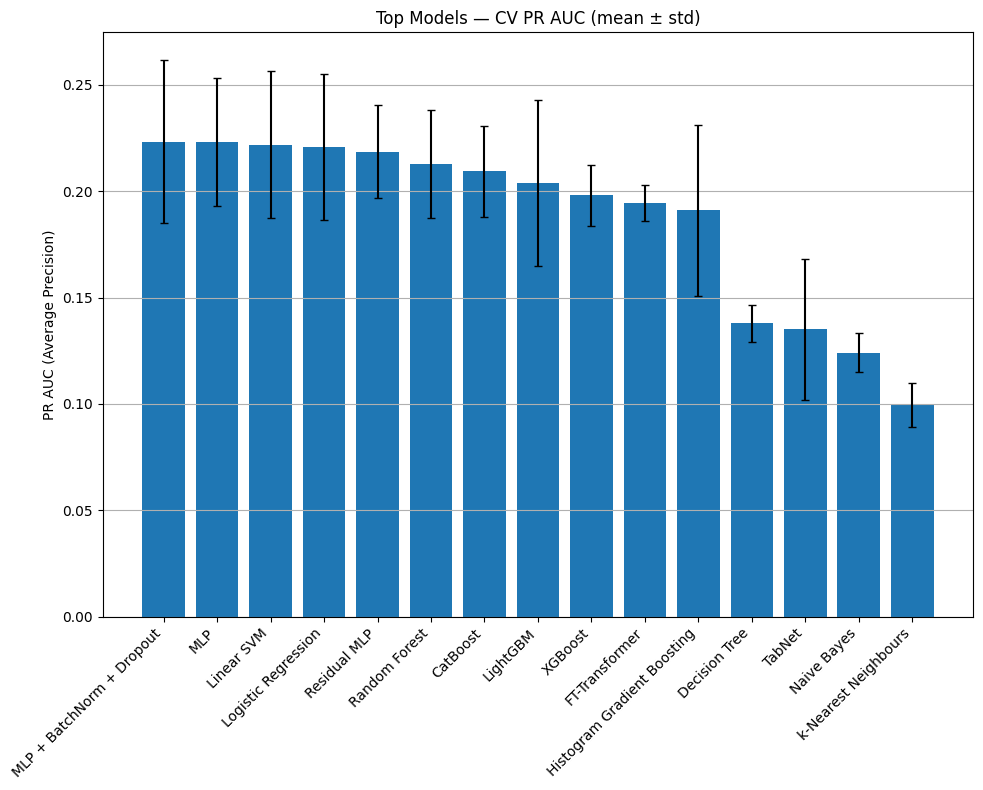

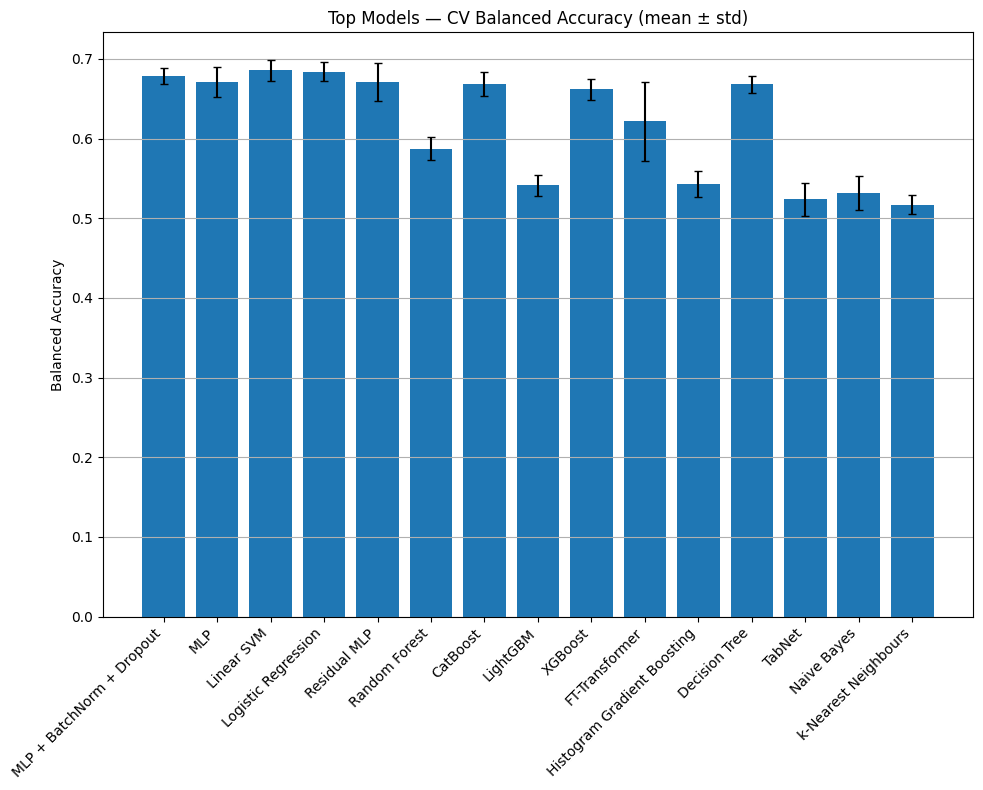

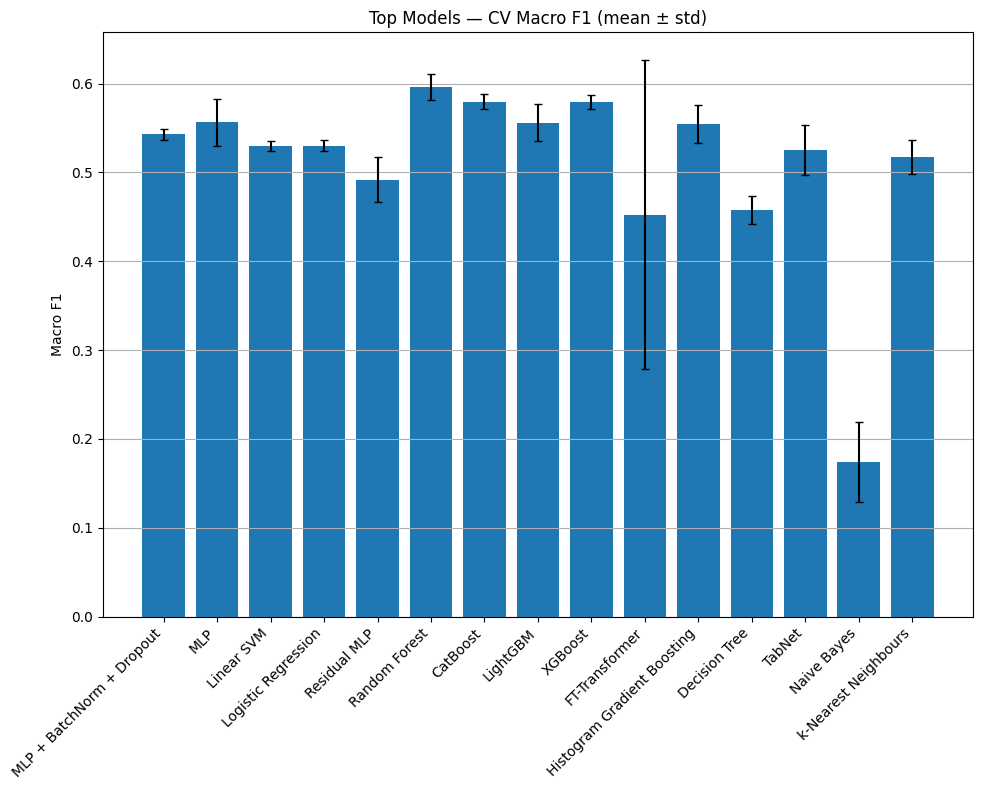

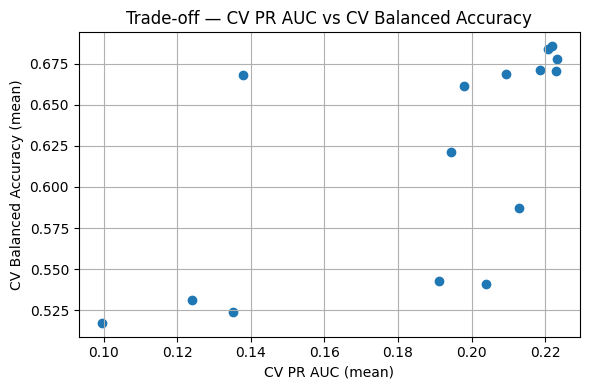

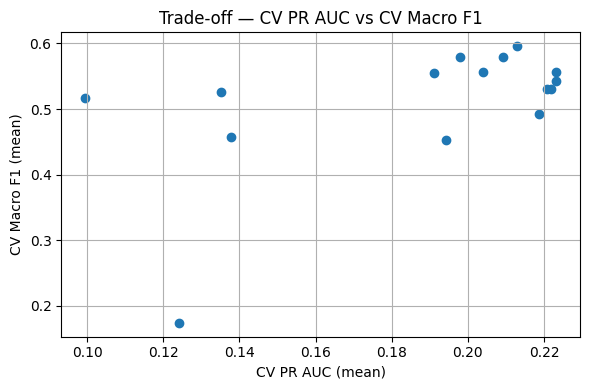

In [40]:
import matplotlib.pyplot as plt

plot_df = leaderboard.copy ().head (top_n)

def bar_with_error (x_labels, y, yerr, title, ylabel):
    plt.figure (figsize = (10, 8))
    plt.bar (x_labels, y, yerr = yerr, capsize = 3)
    plt.title (title)
    plt.ylabel (ylabel)
    plt.xticks (rotation = 45, ha = "right")
    plt.grid (True, axis = "y")
    plt.tight_layout ()
    plt.show ()

bar_with_error (
    plot_df["model"],
    plot_df["cv_pr_auc_mean"],
    plot_df["cv_pr_auc_std"],
    "Top Models — CV PR AUC (mean ± std)",
    "PR AUC (Average Precision)"
)

bar_with_error (
    plot_df["model"],
    plot_df["cv_balanced_accuracy_mean"],
    plot_df["cv_balanced_accuracy_std"],
    "Top Models — CV Balanced Accuracy (mean ± std)",
    "Balanced Accuracy"
)

bar_with_error (
    plot_df["model"],
    plot_df["cv_f1_macro_mean"],
    plot_df["cv_f1_macro_std"],
    "Top Models — CV Macro F1 (mean ± std)",
    "Macro F1"
)

plt.figure (figsize = (6, 4))
plt.scatter (leaderboard["cv_pr_auc_mean"], leaderboard["cv_balanced_accuracy_mean"])
plt.title ("Trade-off — CV PR AUC vs CV Balanced Accuracy")
plt.xlabel ("CV PR AUC (mean)")
plt.ylabel ("CV Balanced Accuracy (mean)")
plt.grid (True)
plt.tight_layout ()
plt.show ()

plt.figure (figsize = (6, 4))
plt.scatter (leaderboard["cv_pr_auc_mean"], leaderboard["cv_f1_macro_mean"])
plt.title ("Trade-off — CV PR AUC vs CV Macro F1")
plt.xlabel ("CV PR AUC (mean)")
plt.ylabel ("CV Macro F1 (mean)")
plt.grid (True)
plt.tight_layout ()
plt.show ()


## Step 4 — Compute insight helpers (stability, generalisation, multi-metric ranking) for our report

We calculate:
- Most stable model: smallest CV PR AUC std  
- Biggest CV→test drop (possible overfit or shift)  
- A simple multi-metric score using rank-sum across:
  - CV PR AUC mean (main)
  - CV Balanced Accuracy mean
  - CV Macro F1 mean
Lower rank-sum is better.


In [42]:
insights = {}

stable = leaderboard.dropna (subset = ["cv_pr_auc_std"]).sort_values ("cv_pr_auc_std", ascending = True).head (5)
drop_big = leaderboard.dropna (subset = ["cv_to_test_pr_auc_drop"]).sort_values ("cv_to_test_pr_auc_drop", ascending = False).head (5)

tmp = leaderboard.copy ()

tmp["rank_pr"] = tmp["cv_pr_auc_mean"].rank (ascending = False, method = "min")
tmp["rank_ba"] = tmp["cv_balanced_accuracy_mean"].rank (ascending = False, method = "min")
tmp["rank_f1"] = tmp["cv_f1_macro_mean"].rank (ascending = False, method = "min")

tmp["rank_sum"] = tmp["rank_pr"] + tmp["rank_ba"] + tmp["rank_f1"]
tmp = tmp.sort_values ("rank_sum", ascending = True).reset_index (drop = True)

print ("Most stable (lowest CV PR AUC std):")
display (stable[["model", "cv_pr_auc_mean", "cv_pr_auc_std"]])

print ("Largest CV → test PR AUC drop:")
display (drop_big[["model", "cv_pr_auc_mean", "test_pr_auc", "cv_to_test_pr_auc_drop"]])

print ("Best overall by simple rank-sum (PR AUC + Balanced Accuracy + Macro F1):")
display (tmp[["model", "cv_pr_auc_mean", "cv_balanced_accuracy_mean", "cv_f1_macro_mean", "rank_sum"]].head (10))


Most stable (lowest CV PR AUC std):


,model,cv_pr_auc_mean,cv_pr_auc_std
9,FT-Transformer,0.194310,0.008409
11,Decision Tree,0.137858,0.008787
13,Naive Bayes,0.124086,0.009220
14,k-Nearest Neighbours,0.099428,0.010298
8,XGBoost,0.198011,0.014241


Largest CV → test PR AUC drop:


,model,cv_pr_auc_mean,test_pr_auc,cv_to_test_pr_auc_drop
1,MLP,0.223033,0.131191,0.091843
0,MLP + BatchNorm + Dropout,0.223258,0.134881,0.088377
4,Residual MLP,0.218562,0.134843,0.083719
2,Linear SVM,0.221918,0.151649,0.070269
3,Logistic Regression,0.220787,0.150866,0.069921


Best overall by simple rank-sum (PR AUC + Balanced Accuracy + Macro F1):


,model,cv_pr_auc_mean,cv_balanced_accuracy_mean,cv_f1_macro_mean,rank_sum
0,MLP + BatchNorm + Dropout,0.223258,0.678035,0.542768,11.0
1,MLP,0.223033,0.670831,0.556531,11.0
2,Linear SVM,0.221918,0.685662,0.530131,13.0
3,Logistic Regression,0.220787,0.684099,0.530194,14.0
4,CatBoost,0.209338,0.668478,0.579426,16.0
5,Random Forest,0.212925,0.587197,0.595913,17.0
6,XGBoost,0.198011,0.661698,0.579506,19.0
7,Residual MLP,0.218562,0.671059,0.491813,21.0
8,LightGBM,0.203915,0.541196,0.556152,25.0
9,Histogram Gradient Boosting,0.191064,0.542725,0.554611,28.0
